# Huấn luyện và đánh giá YOLO11n trên FinalSFD

Notebook đọc FinalSFD đã chốt từ Kaggle Input, class 0=smoke và 1=fire. Dữ liệu nguồn không bị sửa; nhãn hình học lỗi được sửa trên bản sao và ghi báo cáo.

Quy trình: thống kê ảnh/box → minh họa model COCO pretrained → fine-tune YOLO11n ở `imgsz=640` → tùy chọn train từ đầu (scratch) → đánh giá val/test → khảo sát NMS IoU 0.3/0.5/0.7/0.9 với **0.5 là cấu hình chính** → chọn confidence từ val → đánh giá mức ảnh, kích thước box và ảnh sai trên test → đóng gói kết quả.

`RUN_SCRATCH=False` mặc định vì scratch cần thêm nhiều giờ trên T4. Có thể chạy hai phiên: phiên đầu train transfer và tải ZIP kết quả; phiên sau gắn ZIP đó vào Kaggle Input, đặt `TRANSFER_RESULTS_ZIP` và bật `RUN_SCRATCH=True`. Notebook kiểm tra dataset/config trước khi dùng lại checkpoint. Nếu không chạy scratch, notebook ghi rõ chưa có so sánh định lượng. Dự đoán toàn tập test xử lý từng ảnh trên CPU để tránh CUDA out of memory.

NMS IoU là ngưỡng lọc box dự đoán chồng nhau; nó khác IoU khớp box dùng cho mAP50 và mAP50–95.


## Cài thư viện và ghi nhận môi trường

In [1]:
from __future__ import annotations

import gc
import hashlib
import importlib.metadata
import json
import os
import platform
import random
import shutil
import subprocess
import sys
import time
import zipfile
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

ULTRALYTICS_VERSION = "8.4.203"
try:
    installed_version = importlib.metadata.version("ultralytics")
except importlib.metadata.PackageNotFoundError:
    installed_version = None

if installed_version != ULTRALYTICS_VERSION:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        f"ultralytics=={ULTRALYTICS_VERSION}",
    ])

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
import yaml
from IPython.display import FileLink, Image as NotebookImage, display
from ultralytics import YOLO

if not torch.cuda.is_available():
    raise RuntimeError("Chưa có GPU. Hãy chọn GPU trong Kaggle Settings trước khi train.")

print("Python:", platform.python_version())
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python: 3.13.16
Ultralytics: 8.4.203
PyTorch: 2.11.0+cu130
GPU: Tesla T4


## Cấu hình và tìm Kaggle Input

In [2]:
INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
DATASET_OVERRIDE = "/kaggle/input/datasets/quynnguynthanh/finalsfd-yolo-dataset/FinalSFD_YOLO_Dataset"  # Kaggle Dataset bạn đã tải lên.
DATASET_ZIP_NAME = "FinalSFD_YOLO_Dataset.zip"
RUN_ID = "final_sfd_yolo11n_" + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
RUN_DIR = WORK_ROOT / RUN_ID
RESULT_ZIP = WORK_ROOT / f"{RUN_ID}_results.zip"

IMAGE_SIZE = 640
BATCH_SIZE = 32
EPOCHS = 250
PATIENCE = 20
WORKERS = 4
SEED = 0
EVAL_CONF = 0.001
VIS_CONF = 0.25
NMS_IOU = 0.5
IOU_SWEEP = (0.3, 0.5, 0.7, 0.9)
RUN_SCRATCH = True  # True: train từ đầu để so sánh; tốn thêm nhiều giờ.
TRANSFER_RESULTS_ZIP = "/kaggle/input/notebooks/vuongnggg/train-yolo11n-final-sfd-v2/final_sfd_yolo11n_20261112_042400_results.zip"  # Phiên 2: ZIP kết quả của phiên 1 với notebook này và NMS IoU 0.5.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def has_dataset_layout(folder: Path) -> bool:
    return (folder / "data.yaml").is_file() and all(
        (folder / "images" / split).is_dir() and (folder / "labels" / split).is_dir()
        for split in ("train", "val", "test")
    )


def find_dataset_source() -> Path:
    # Dữ liệu do người dùng tải lên nằm ngoài nhánh /kaggle/input/notebooks/.
    # Không tự chọn output cũ của Data_Preprocessing_YOLO khi cả hai cùng tên.
    def uploaded(path: Path) -> bool:
        return "notebooks" not in path.relative_to(INPUT_ROOT).parts

    if DATASET_OVERRIDE is not None:
        candidate = Path(DATASET_OVERRIDE).expanduser().resolve()
        if candidate.is_file() and candidate.suffix.lower() == ".zip":
            return candidate
        if candidate.is_dir():
            roots = [candidate] if has_dataset_layout(candidate) else [
                path.parent for path in candidate.rglob("data.yaml") if has_dataset_layout(path.parent)
            ]
            if len(roots) == 1:
                return roots[0].resolve()
            if not roots:
                archives = sorted(candidate.rglob(DATASET_ZIP_NAME))
                if len(archives) == 1:
                    return archives[0].resolve()
        raise RuntimeError(f"DATASET_OVERRIDE không trỏ đến một ZIP hoặc bộ FinalSFD hợp lệ: {candidate}")

    archives = sorted(path.resolve() for path in INPUT_ROOT.rglob(DATASET_ZIP_NAME)
                      if path.is_file() and uploaded(path))
    directories = sorted({path.parent.resolve() for path in INPUT_ROOT.rglob("data.yaml")
                          if uploaded(path) and has_dataset_layout(path.parent)})
    candidates = archives + directories
    if len(candidates) == 1:
        return candidates[0]
    if not candidates:
        raise FileNotFoundError(
            f"Không thấy {DATASET_ZIP_NAME} hoặc thư mục images/labels/data.yaml "
            f"trong Kaggle Dataset đã tải lên. Kiểm tra Kaggle Input hoặc đặt DATASET_OVERRIDE."
        )
    raise RuntimeError(
        f"Có nhiều nguồn FinalSFD được tải lên: {candidates}. "
        "Đặt DATASET_OVERRIDE thành đường dẫn ZIP hoặc thư mục cần train."
    )


def extract_dataset_zip(source_zip: Path, destination: Path) -> tuple[int, int, dict]:
    destination.mkdir(parents=True)
    root = destination.resolve()
    with zipfile.ZipFile(source_zip) as archive:
        infos = [info for info in archive.infolist() if not info.is_dir()]
        names = {info.filename for info in infos}
        # Một số notebook Kaggle nén cả đường dẫn kaggle/working/<dataset>/.
        # Chọn tiền tố duy nhất chứa data.yaml và đủ ba tập, không giả định gốc ZIP.
        prefixes = sorted({name[:-len("data.yaml")] for name in names if name.endswith("data.yaml")})
        valid_prefixes = [prefix for prefix in prefixes if all(
            any(name.startswith(prefix + f"images/{split}/") for name in names)
            and any(name.startswith(prefix + f"labels/{split}/") for name in names)
            for split in ("train", "val", "test")
        )]
        if len(valid_prefixes) != 1:
            raise RuntimeError(
                f"Cần đúng một gốc dữ liệu trong ZIP; tìm thấy {valid_prefixes}. "
                f"data.yaml ứng viên: {prefixes[:10]}"
            )
        prefix = valid_prefixes[0]
        members = [info for info in infos if info.filename.startswith(prefix)]
        source_image_counts = {
            split: sum(
                info.filename.startswith(prefix + f"images/{split}/")
                and Path(info.filename).suffix.lower() in IMAGE_EXTENSIONS
                for info in members
            )
            for split in ("train", "val", "test")
        }
        total_bytes = sum(info.file_size for info in members)
        reserve_bytes = 2 * 1024**3
        free_bytes = shutil.disk_usage(WORK_ROOT).free
        if free_bytes < total_bytes + reserve_bytes:
            raise RuntimeError(
                f"Không đủ dung lượng giải nén: cần {(total_bytes + reserve_bytes) / 1024**3:.2f} GB, "
                f"còn {free_bytes / 1024**3:.2f} GB"
            )
        for info in members:
            original = Path(info.filename)
            relative = Path(info.filename[len(prefix):])
            target = (root / relative).resolve()
            if (original.is_absolute() or ".." in original.parts or relative.is_absolute()
                    or target == root or not target.is_relative_to(root)
                    or (info.external_attr >> 16) & 0o170000 == 0o120000):
                raise RuntimeError(f"Đường dẫn không an toàn trong ZIP: {info.filename}")
            target.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(info) as source, target.open("wb") as output:
                shutil.copyfileobj(source, output, length=1024 * 1024)
    print("Thư mục gốc trong ZIP:", prefix or "(gốc ZIP)")
    return total_bytes, len(members), source_image_counts


DATASET_SOURCE = find_dataset_source()
if RUN_DIR.exists() or RESULT_ZIP.exists():
    raise FileExistsError(f"Run đã tồn tại: {RUN_DIR} hoặc {RESULT_ZIP}. Hãy chạy lại ô cấu hình để tạo RUN_ID mới.")
RUN_DIR.mkdir(parents=True)
(RUN_DIR / "reports").mkdir()
LOCAL_DATASET_ROOT = RUN_DIR / "dataset_local"

copy_started = time.perf_counter()
if DATASET_SOURCE.is_file():
    source_bytes, copied_files, source_image_counts = extract_dataset_zip(DATASET_SOURCE, LOCAL_DATASET_ROOT)
    copy_method = "extract_zip"
else:
    source_files = [path for path in DATASET_SOURCE.rglob("*") if path.is_file()]
    source_bytes = sum(path.stat().st_size for path in source_files)
    reserve_bytes = 2 * 1024**3
    free_bytes = shutil.disk_usage(WORK_ROOT).free
    if free_bytes < source_bytes + reserve_bytes:
        raise RuntimeError(f"Không đủ dung lượng sao chép: cần {(source_bytes + reserve_bytes) / 1024**3:.2f} GB, còn {free_bytes / 1024**3:.2f} GB")
    shutil.copytree(DATASET_SOURCE, LOCAL_DATASET_ROOT)
    copied_files = len(source_files)
    copy_method = "copy_directory"
    source_image_counts = {split: sum(
        path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
        for path in (DATASET_SOURCE / "images" / split).iterdir()
    ) for split in ("train", "val", "test")}
copy_seconds = time.perf_counter() - copy_started
if not has_dataset_layout(LOCAL_DATASET_ROOT):
    raise RuntimeError(f"Bản dữ liệu cục bộ thiếu ảnh hoặc nhãn: {LOCAL_DATASET_ROOT}")

SOURCE_YAML = LOCAL_DATASET_ROOT / "data.yaml"
source_config = yaml.safe_load(SOURCE_YAML.read_text(encoding="utf-8"))
names = source_config.get("names")
if isinstance(names, dict):
    names = [names[key] for key in sorted(names, key=lambda value: int(value))]
if source_config.get("nc") != 2 or [str(name).lower() for name in names or []] != ["smoke", "fire"]:
    raise RuntimeError(f"Class map phải là 0=smoke, 1=fire; hiện tại: {names}")

TRAIN_YAML = RUN_DIR / "data_for_training.yaml"
TRAIN_YAML.write_text(yaml.safe_dump({
    "path": str(LOCAL_DATASET_ROOT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 2,
    "names": {0: "smoke", 1: "fire"},
}, sort_keys=False, allow_unicode=True), encoding="utf-8")

print("Dataset Kaggle:", DATASET_SOURCE)
print("Dung lượng ZIP/tập nguồn (GiB):", round(DATASET_SOURCE.stat().st_size / 1024**3, 3) if DATASET_SOURCE.is_file() else "thư mục")
print("Số ảnh trong nguồn:", source_image_counts)
print("Bản dữ liệu cục bộ:", LOCAL_DATASET_ROOT)
print("Phương pháp:", copy_method, "số file:", copied_files)
print("Dung lượng dữ liệu (GB):", round(source_bytes / 1024**3, 2))
print("Thời gian chuẩn bị (giây):", round(copy_seconds, 1))
print("YAML train:", TRAIN_YAML)
print("Thư mục run:", RUN_DIR)
print("ZIP kết quả sẽ tạo:", RESULT_ZIP)


Dataset Kaggle: /kaggle/input/datasets/quynnguynthanh/finalsfd-yolo-dataset/FinalSFD_YOLO_Dataset
Dung lượng ZIP/tập nguồn (GiB): thư mục
Số ảnh trong nguồn: {'train': 13293, 'val': 2342, 'test': 3857}
Bản dữ liệu cục bộ: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local
Phương pháp: copy_directory số file: 38985
Dung lượng dữ liệu (GB): 2.44
Thời gian chuẩn bị (giây): 3404.8
YAML train: /kaggle/working/final_sfd_yolo11n_20261112_170520/data_for_training.yaml
Thư mục run: /kaggle/working/final_sfd_yolo11n_20261112_170520
ZIP kết quả sẽ tạo: /kaggle/working/final_sfd_yolo11n_20261112_170520_results.zip


## Kiểm tra ảnh, nhãn và thống kê trước train

ZIP FinalSFD còn một số box vượt mép ảnh và box có kích thước bằng 0. Notebook chỉ sửa bản nhãn đã sao chép vào `/kaggle/working`: cắt box về biên ảnh, bỏ box không còn diện tích và ghi `reports/label_fixes.csv`. Ảnh, nhãn nguồn trong Kaggle Input không đổi. Thống kê và metrics dùng bản nhãn đã sửa; số ảnh ở mỗi tập giữ nguyên.


Sửa nhãn cục bộ: {'clip_to_image': 379, 'drop_zero_area': 18, 'affected_labels': 340}
Đối chiếu nguồn và bản giải nén: {'train': 13293, 'val': 2342, 'test': 3857} (khớp)


,images,fire_only,smoke_only,both,background,fire_present,smoke_present,fire_boxes,smoke_boxes
split,,,,,,,,,
train,13293,2254,4454,3927,2658,6181,8381,13706,10024
val,2342,397,785,692,468,1089,1477,2392,1736
test,3857,647,1327,1111,772,1758,2438,3897,2871


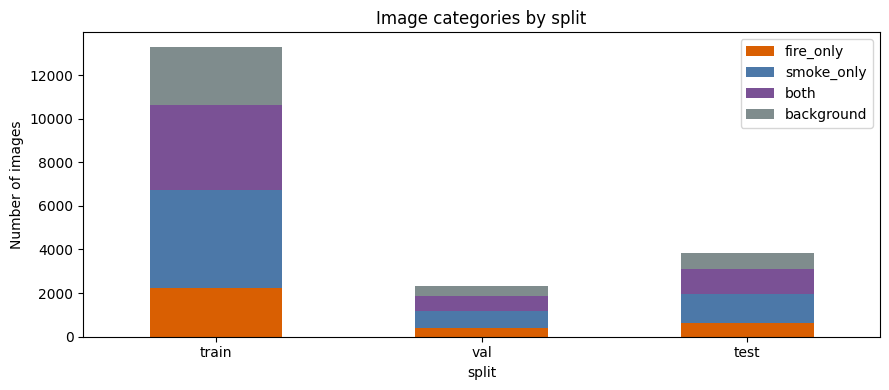

In [3]:
def repair_local_labels() -> pd.DataFrame:
    fixes = []
    for split in ("train", "val", "test"):
        for label_path in sorted((LOCAL_DATASET_ROOT / "labels" / split).glob("*.txt")):
            original_lines = label_path.read_text(encoding="utf-8-sig").splitlines()
            corrected_lines = []
            changed = False
            for line_number, line in enumerate(original_lines, 1):
                fields = line.split()
                if not fields:
                    continue
                if len(fields) != 5 or fields[0] not in {"0", "1"}:
                    raise RuntimeError(f"Nhãn không đúng YOLO box: {label_path}:{line_number}")
                try:
                    x, y, width, height = (float(value) for value in fields[1:])
                except ValueError as error:
                    raise RuntimeError(f"Không đọc được tọa độ: {label_path}:{line_number}") from error
                if not all(np.isfinite(value) for value in (x, y, width, height)):
                    raise RuntimeError(f"Tọa độ không hữu hạn: {label_path}:{line_number}")

                left, right = x - width / 2, x + width / 2
                top, bottom = y - height / 2, y + height / 2
                clipped_left, clipped_right = max(0.0, left), min(1.0, right)
                clipped_top, clipped_bottom = max(0.0, top), min(1.0, bottom)
                if (width <= 0 or height <= 0 or clipped_right <= clipped_left
                        or clipped_bottom <= clipped_top):
                    action, corrected = "drop_zero_area", ""
                elif (any(value < 0 or value > 1 for value in (x, y, width, height))
                      or max(abs(clipped_left - left), abs(clipped_right - right),
                             abs(clipped_top - top), abs(clipped_bottom - bottom)) > 1e-6):
                    new_x = (clipped_left + clipped_right) / 2
                    new_y = (clipped_top + clipped_bottom) / 2
                    new_width = clipped_right - clipped_left
                    new_height = clipped_bottom - clipped_top
                    action = "clip_to_image"
                    corrected = f"{fields[0]} {new_x:.12g} {new_y:.12g} {new_width:.12g} {new_height:.12g}"
                else:
                    action, corrected = "keep", line

                if action != "keep":
                    changed = True
                    fixes.append({
                        "split": split,
                        "label": label_path.relative_to(LOCAL_DATASET_ROOT).as_posix(),
                        "line": line_number,
                        "action": action,
                        "before": line,
                        "after": corrected,
                    })
                if corrected:
                    corrected_lines.append(corrected)
            if changed:
                label_path.write_text("\n".join(corrected_lines) + ("\n" if corrected_lines else ""), encoding="utf-8")
    return pd.DataFrame(fixes, columns=["split", "label", "line", "action", "before", "after"])


label_fixes = repair_local_labels()
label_fixes.to_csv(RUN_DIR / "reports" / "label_fixes.csv", index=False)
label_fix_summary = {
    "clip_to_image": int((label_fixes["action"] == "clip_to_image").sum()),
    "drop_zero_area": int((label_fixes["action"] == "drop_zero_area").sum()),
    "affected_labels": int(label_fixes["label"].nunique()),
}
(RUN_DIR / "reports" / "label_fix_summary.json").write_text(
    json.dumps(label_fix_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Sửa nhãn cục bộ:", label_fix_summary)


def inspect_split(split: str) -> dict:
    image_dir = LOCAL_DATASET_ROOT / "images" / split
    label_dir = LOCAL_DATASET_ROOT / "labels" / split
    images = sorted(path for path in image_dir.iterdir() if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS)
    labels = sorted(label_dir.glob("*.txt"))
    image_stems = {path.stem for path in images}
    if not images:
        raise RuntimeError(f"Tập {split} không có ảnh")
    if len(image_stems) != len(images):
        raise RuntimeError(f"Tập {split} có ảnh trùng tên gốc ở nhiều định dạng")
    orphan_labels = [path.name for path in labels if path.stem not in image_stems]
    if orphan_labels:
        raise RuntimeError(f"{split} có nhãn không khớp ảnh: {orphan_labels[:5]}")

    categories = Counter()
    boxes = Counter()
    records = []
    # Ảnh nền có nhãn rỗng; nền không phải lớp thứ ba.
    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"
        if not label_path.is_file():
            raise RuntimeError(f"Thiếu nhãn: {label_path}")
        present = set()
        for line_number, line in enumerate(label_path.read_text(encoding="utf-8-sig").splitlines(), 1):
            fields = line.split()
            if not fields:
                continue
            if len(fields) != 5 or fields[0] not in {"0", "1"}:
                raise RuntimeError(f"Nhãn không đúng YOLO box: {label_path}:{line_number}")
            values = [float(value) for value in fields[1:]]
            if not all(np.isfinite(value) for value in values):
                raise RuntimeError(f"Tọa độ không hữu hạn: {label_path}:{line_number}")
            x, y, width, height = values
            if width <= 0 or height <= 0 or any(value < 0 or value > 1 for value in values):
                raise RuntimeError(f"Tọa độ không hợp lệ: {label_path}:{line_number}")
            if x - width / 2 < -1e-6 or x + width / 2 > 1 + 1e-6:
                raise RuntimeError(f"Box vượt ảnh: {label_path}:{line_number}")
            if y - height / 2 < -1e-6 or y + height / 2 > 1 + 1e-6:
                raise RuntimeError(f"Box vượt ảnh: {label_path}:{line_number}")
            class_id = int(fields[0])
            present.add(class_id)
            boxes[class_id] += 1

        category = (
            "fire_only" if present == {1} else
            "smoke_only" if present == {0} else
            "both" if present == {0, 1} else "background"
        )
        categories[category] += 1
        records.append({"split": split, "image": str(image_path), "category": category})

    return {"images": len(images), "categories": categories, "boxes": boxes, "records": records}


audit = {split: inspect_split(split) for split in ("train", "val", "test")}
actual_image_counts = {split: item["images"] for split, item in audit.items()}
if actual_image_counts != source_image_counts:
    raise RuntimeError(f"Số ảnh sau giải nén/sao chép khác nguồn: nguồn={source_image_counts}, thực tế={actual_image_counts}")
print("Đối chiếu nguồn và bản giải nén:", actual_image_counts, "(khớp)")
image_records = pd.DataFrame(record for item in audit.values() for record in item["records"])
dataset_rows = []
for split, item in audit.items():
    counts = item["categories"]
    dataset_rows.append({
        "split": split, "images": item["images"],
        "fire_only": counts["fire_only"], "smoke_only": counts["smoke_only"],
        "both": counts["both"], "background": counts["background"],
        "fire_present": counts["fire_only"] + counts["both"],
        "smoke_present": counts["smoke_only"] + counts["both"],
        "fire_boxes": item["boxes"][1], "smoke_boxes": item["boxes"][0],
    })
dataset_table = pd.DataFrame(dataset_rows).set_index("split")
display(dataset_table)
dataset_table.to_csv(RUN_DIR / "reports" / "dataset_summary.csv")
(RUN_DIR / "reports" / "dataset_summary.json").write_text(
    json.dumps(dataset_rows, ensure_ascii=False, indent=2), encoding="utf-8"
)

fig, axis = plt.subplots(figsize=(9, 4))
dataset_table[["fire_only", "smoke_only", "both", "background"]].plot.bar(
    stacked=True, ax=axis, rot=0,
    color=["#d95f02", "#4c78a8", "#7a5195", "#7f8c8d"],
)
axis.set_title("Image categories by split")
axis.set_ylabel("Number of images")
fig.tight_layout()
fig.savefig(RUN_DIR / "reports" / "dataset_distribution.png", dpi=160)
display(fig)
plt.close(fig)

## Phân tích tỷ lệ lớp và kích thước box

Diện tích box là tỷ lệ của ảnh gốc. Nhóm `<1%`, `1–10%`, `≥10%` dùng để chẩn đoán bộ này; không phải nhóm small/medium/large của COCO.


,split,class,boxes,median_area,mean_area
0,test,fire,3897,0.008053,0.045854
1,test,smoke,2871,0.141690,0.220708
2,train,fire,13706,0.007919,0.043880
3,train,smoke,10024,0.142949,0.221575
4,val,fire,2392,0.007631,0.042669
5,val,smoke,1736,0.139957,0.224403


size_group    1–10%     <1%    ≥10%
split class                        
test  fire   1256.0  2127.0   514.0
      smoke   717.0   498.0  1656.0
train fire   4485.0  7593.0  1628.0
      smoke  2568.0  1623.0  5833.0
val   fire    777.0  1342.0   273.0
      smoke   473.0   270.0   993.0

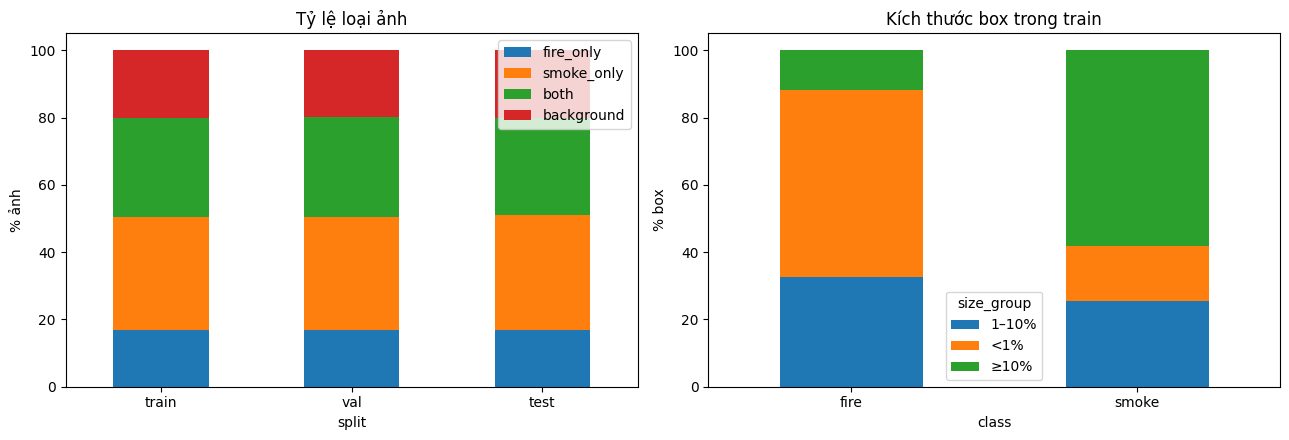

Ảnh có khói/lửa: 8381 6181
Box khói/lửa: 10024 13706
Diện tích box trung vị lửa/khói: 0.007918836805555557 0.14294912855905556
Chưa kết luận nguyên nhân yếu của lớp lửa chỉ từ số ảnh; xem thêm recall theo kích thước ở cuối.


In [4]:
box_rows = []
for split in ("train", "val", "test"):
    for label_path in (LOCAL_DATASET_ROOT / "labels" / split).glob("*.txt"):
        for line in label_path.read_text(encoding="utf-8").splitlines():
            if not line.strip():
                continue
            class_id, _, _, width, height = line.split()
            area = float(width) * float(height)
            size_group = "<1%" if area < 0.01 else "1–10%" if area < 0.10 else "≥10%"
            box_rows.append({"split": split, "class": "smoke" if class_id == "0" else "fire",
                             "normalized_area": area, "size_group": size_group})
box_data = pd.DataFrame(box_rows)
box_size_table = box_data.groupby(["split", "class", "size_group"]).size().rename("boxes").reset_index()
box_size_table.to_csv(RUN_DIR / "reports" / "box_size_distribution.csv", index=False)
area_table = box_data.groupby(["split", "class"])["normalized_area"].agg(
    boxes="size", median_area="median", mean_area="mean"
).reset_index()
area_table.to_csv(RUN_DIR / "reports" / "box_area_summary.csv", index=False)
display(area_table)
display(box_size_table.pivot_table(index=["split", "class"], columns="size_group",
                             values="boxes", fill_value=0))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
dataset_table[["fire_only", "smoke_only", "both", "background"]].div(
    dataset_table["images"], axis=0
).mul(100).plot.bar(stacked=True, ax=axes[0], rot=0)
axes[0].set(title="Tỷ lệ loại ảnh", ylabel="% ảnh")
train_sizes = box_size_table[box_size_table["split"] == "train"].pivot(
    index="class", columns="size_group", values="boxes"
).fillna(0)
train_sizes.div(train_sizes.sum(axis=1), axis=0).mul(100).plot.bar(
    stacked=True, ax=axes[1], rot=0
)
axes[1].set(title="Kích thước box trong train", ylabel="% box")
fig.tight_layout()
fig.savefig(RUN_DIR / "reports" / "data_balance_and_box_size.png", dpi=150)
display(fig)
plt.close(fig)
train_fire_images = int(dataset_table.loc["train", "fire_present"])
train_smoke_images = int(dataset_table.loc["train", "smoke_present"])
train_fire_boxes = int(dataset_table.loc["train", "fire_boxes"])
train_smoke_boxes = int(dataset_table.loc["train", "smoke_boxes"])
train_area = area_table[area_table["split"] == "train"].set_index("class")
imbalance_diagnosis = {
    "fire_present_images": train_fire_images, "smoke_present_images": train_smoke_images,
    "smoke_to_fire_image_ratio": train_smoke_images / train_fire_images,
    "fire_boxes": train_fire_boxes, "smoke_boxes": train_smoke_boxes,
    "fire_to_smoke_box_ratio": train_fire_boxes / train_smoke_boxes,
    "median_fire_box_area": float(train_area.loc["fire", "median_area"]),
    "median_smoke_box_area": float(train_area.loc["smoke", "median_area"]),
}
(RUN_DIR / "reports" / "imbalance_diagnosis.json").write_text(
    json.dumps(imbalance_diagnosis, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Ảnh có khói/lửa:", train_smoke_images, train_fire_images)
print("Box khói/lửa:", train_smoke_boxes, train_fire_boxes)
print("Diện tích box trung vị lửa/khói:", imbalance_diagnosis["median_fire_box_area"],
      imbalance_diagnosis["median_smoke_box_area"])
print("Chưa kết luận nguyên nhân yếu của lớp lửa chỉ từ số ảnh; xem thêm recall theo kích thước ở cuối.")


## Minh họa checkpoint COCO trước fine-tune

In tên lớp từ chính `yolo11n.pt` và thử trên một nhóm ảnh val cố định. Không tính mAP khói/lửa trực tiếp cho model COCO vì ID 80 lớp của nó khác ID hai lớp FinalSFD. `fire hydrant` là trụ cứu hỏa, không phải ngọn lửa.


Số lớp của checkpoint COCO: 80
Lớp smoke/fire/flame đúng nghĩa: không có
Tên lớp chứa từ fire: ['fire hydrant']


,image,true_category,coco_predictions,annotated_file
0,dbafire_dbafire_01653.jpg,fire_only,car,dbafire_dbafire_01653.jpg
1,dfire_WEB05999.jpg,fire_only,,dfire_WEB05999.jpg
2,dfire_PublicDataset00802.jpg,smoke_only,,dfire_PublicDataset00802.jpg
3,dbafire_dbafire_02632.jpg,smoke_only,surfboard,dbafire_dbafire_02632.jpg
4,dfire_WEB03851.jpg,both,,dfire_WEB03851.jpg
5,dfire_WEB06205.jpg,both,person,dfire_WEB06205.jpg
6,flame_lake_resized_lake_frame1021.jpg,background,,flame_lake_resized_lake_frame1021.jpg
7,dfire_WEB02365.jpg,background,,dfire_WEB02365.jpg


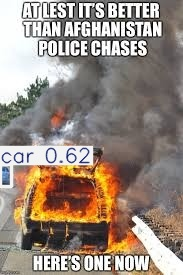

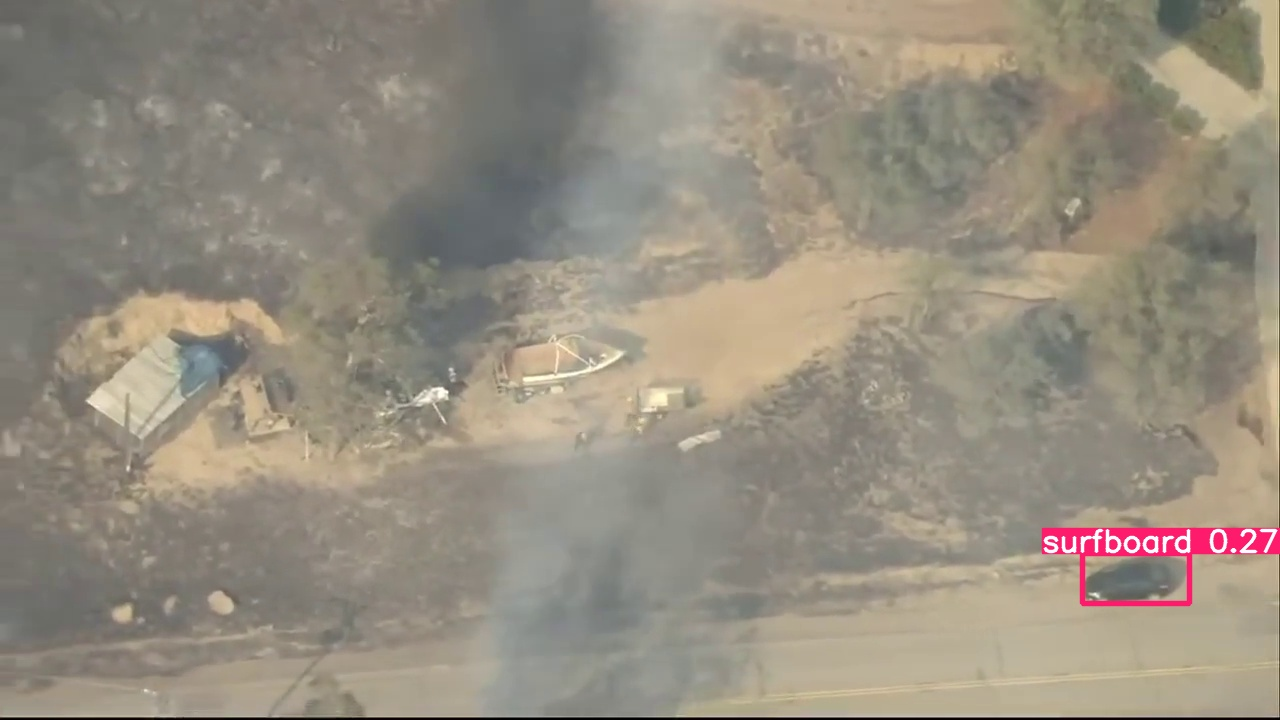

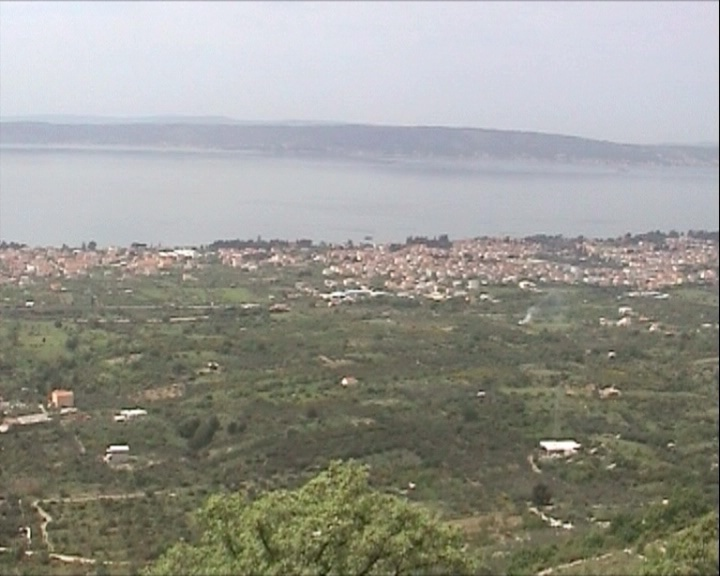

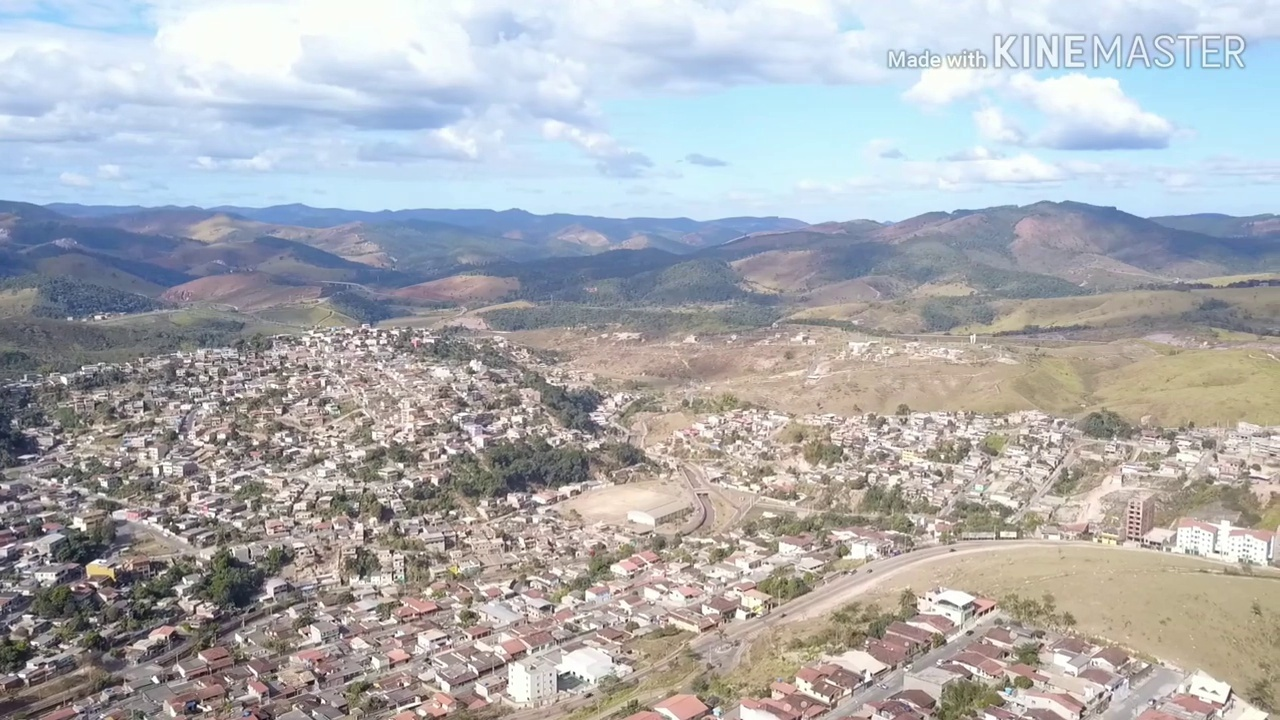

In [5]:
os.chdir(RUN_DIR)
pretrained_model = YOLO("yolo11n.pt")
coco_names = {int(key): str(value) for key, value in pretrained_model.names.items()}
target_names = {"smoke", "fire", "flame"}
present_targets = {key: name for key, name in coco_names.items() if name.lower() in target_names}
print("Số lớp của checkpoint COCO:", len(coco_names))
print("Lớp smoke/fire/flame đúng nghĩa:", present_targets or "không có")
print("Tên lớp chứa từ fire:", [name for name in coco_names.values() if "fire" in name.lower()])
(RUN_DIR / "reports" / "pretrained_class_names.json").write_text(
    json.dumps(coco_names, ensure_ascii=False, indent=2), encoding="utf-8"
)
val_records = image_records[image_records["split"] == "val"]
sample_rng = random.Random(SEED)
pretrained_paths = []
for category in ("fire_only", "smoke_only", "both", "background"):
    candidates = sorted(val_records.loc[val_records["category"] == category, "image"].tolist())
    pretrained_paths.extend(sample_rng.sample(candidates, min(2, len(candidates))))
pretrained_dir = RUN_DIR / "reports" / "pretrained_examples"
pretrained_dir.mkdir(parents=True, exist_ok=True)
pretrained_rows = []
for path in pretrained_paths:
    result = pretrained_model.predict(path, imgsz=IMAGE_SIZE, conf=VIS_CONF, iou=NMS_IOU,
                                      device="cpu", batch=1, verbose=False)[0]
    predicted_names = [result.names[int(class_id)] for class_id in result.boxes.cls.cpu().tolist()]
    output_path = pretrained_dir / Path(path).name
    result.save(filename=str(output_path))
    pretrained_rows.append({"image": Path(path).name,
                            "true_category": val_records.loc[val_records["image"] == path, "category"].iloc[0],
                            "coco_predictions": ", ".join(predicted_names), "annotated_file": output_path.name})
    del result
pretrained_table = pd.DataFrame(pretrained_rows)
pretrained_table.to_csv(RUN_DIR / "reports" / "pretrained_examples.csv", index=False)
display(pretrained_table)
for output_path in sorted(pretrained_dir.iterdir())[:4]:
    display(NotebookImage(filename=str(output_path), width=460))
del pretrained_model
gc.collect()
torch.cuda.empty_cache()


## Huấn luyện YOLO11n transfer hoặc dùng lại checkpoint

Phiên đầu để `TRANSFER_RESULTS_ZIP=None`: train từ `yolo11n.pt` với `imgsz=640`, NMS IoU 0.5 khi chọn best.pt trên val. Nếu cần chạy scratch ở phiên Kaggle thứ hai, gắn ZIP kết quả phiên đầu vào Input, đặt đường dẫn `TRANSFER_RESULTS_ZIP` và bật `RUN_SCRATCH=True`. Notebook kiểm tra nguồn/cấu hình trước khi dùng lại checkpoint; ZIP cũ với IoU 0.7 không được chấp nhận cho so sánh kiểm soát.


In [6]:
# Có thể dùng lại transfer checkpoint từ phiên đầu để chạy scratch ở phiên thứ hai.
os.chdir(RUN_DIR)
TRAIN_DIR = RUN_DIR / "train"
BEST_PT = TRAIN_DIR / "weights" / "best.pt"
transfer_reused = TRANSFER_RESULTS_ZIP is not None
if transfer_reused:
    source_results = Path(TRANSFER_RESULTS_ZIP).expanduser().resolve()
    if not source_results.is_file() or source_results.suffix.lower() != ".zip":
        raise FileNotFoundError(f"Không thấy ZIP kết quả transfer: {source_results}")
    with zipfile.ZipFile(source_results) as archive:
        required = {"best.pt", "train/results.csv", "reports/run_summary.json"}
        if not required.issubset(archive.namelist()):
            raise RuntimeError(f"ZIP transfer thiếu: {sorted(required - set(archive.namelist()))}")
        previous = json.loads(archive.read("reports/run_summary.json"))
        if (previous.get("nms_iou_main") != NMS_IOU
                or previous.get("dataset_yaml_sha256") != hashlib.sha256(SOURCE_YAML.read_bytes()).hexdigest()
                or previous.get("dataset_images") != dataset_rows
                or previous.get("local_label_fixes") != label_fix_summary
                or previous.get("training", {}).get("imgsz") != IMAGE_SIZE
                or previous.get("training", {}).get("batch") != BATCH_SIZE
                or previous.get("training", {}).get("seed") != SEED
                or previous.get("training", {}).get("epochs_max") != EPOCHS
                or previous.get("training", {}).get("patience") != PATIENCE):
            raise RuntimeError("ZIP transfer không cùng dataset/cấu hình NMS IoU 0.5, imgsz, batch, seed. "
                               "Hãy dùng ZIP tạo từ phiên đầu của chính notebook mới này.")
        BEST_PT.parent.mkdir(parents=True, exist_ok=True)
        BEST_PT.write_bytes(archive.read("best.pt"))
        (TRAIN_DIR / "results.csv").write_bytes(archive.read("train/results.csv"))
        if "train/results.png" in archive.namelist():
            (TRAIN_DIR / "results.png").write_bytes(archive.read("train/results.png"))
    training_seconds = 0.0
    print("Dùng lại transfer best.pt:", BEST_PT)
else:
    train_started = time.perf_counter()
    train_model = YOLO("yolo11n.pt")
    train_model.train(
        data=str(TRAIN_YAML), epochs=EPOCHS, imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
        patience=PATIENCE, iou=NMS_IOU, seed=SEED, deterministic=True,
        workers=WORKERS, device=0, project=str(RUN_DIR), name="train",
        exist_ok=True, plots=True, save=True, cache=False,
    )
    training_seconds = time.perf_counter() - train_started
    TRAIN_DIR = Path(train_model.trainer.save_dir).resolve()
    BEST_PT = TRAIN_DIR / "weights" / "best.pt"
    del train_model
    gc.collect()
    torch.cuda.empty_cache()
if not BEST_PT.is_file():
    raise FileNotFoundError(f"Không có checkpoint transfer: {BEST_PT}")
print("Checkpoint transfer:", BEST_PT)
print("Thời gian train transfer trong phiên này (giây):", round(training_seconds, 1))


Dùng lại transfer best.pt: /kaggle/working/final_sfd_yolo11n_20261112_170520/train/weights/best.pt
Checkpoint transfer: /kaggle/working/final_sfd_yolo11n_20261112_170520/train/weights/best.pt
Thời gian train transfer trong phiên này (giây): 0.0


## Đối chứng train từ đầu (tùy chọn)

Khi `RUN_SCRATCH=True`, YOLO11n được khởi tạo từ `yolo11n.yaml`, dùng cùng dữ liệu, seed, `imgsz=640`, batch, giới hạn epochs và patience như run fine-tune. Hai checkpoint đều chọn bằng validation.


In [7]:
SCRATCH_PT = None
scratch_training_seconds = None
if RUN_SCRATCH:
    scratch_started = time.perf_counter()
    scratch_model = YOLO("yolo11n.yaml")
    scratch_model.train(
        data=str(TRAIN_YAML), epochs=EPOCHS, imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
        patience=PATIENCE, seed=SEED, deterministic=True, workers=WORKERS,
        iou=NMS_IOU, pretrained=False,
        device=0, project=str(RUN_DIR), name="scratch", exist_ok=True,
        plots=True, save=True, cache=False,
    )
    scratch_training_seconds = time.perf_counter() - scratch_started
    SCRATCH_PT = Path(scratch_model.trainer.save_dir) / "weights" / "best.pt"
    if not SCRATCH_PT.is_file():
        raise FileNotFoundError(f"Không có checkpoint scratch: {SCRATCH_PT}")
    print("Scratch best.pt:", SCRATCH_PT, "thời gian (giờ):", round(scratch_training_seconds / 3600, 2))
    del scratch_model
    gc.collect()
    torch.cuda.empty_cache()
else:
    print("Chưa chạy scratch. Không kết luận transfer tốt hơn scratch từ run này.")


New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/final_sfd_yolo11n_20261112_170520/data_for_training.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=250, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.5, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/250       6.6G      2.513      2.866      2.798         58        640: 100% ━━━━━━━━━━━━ 416/416 3.7it/s 1:52
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 3.5it/s 10.7s
                   all       2342       4128      0.242      0.263      0.146     0.0433

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/250       6.6G      2.076      2.364      2.216         63        640: 100% ━━━━━━━━━━━━ 416/416 3.8it/s 1:49
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 3.5it/s 10.7s
                   all       2342       4128      0.255      0.308      0.191     0.0578

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/250       6.6G      1.946      2.178          2         69        640: 100% ━━━━━━━━━━━━ 416/416 3.8it/s 1:51
                 Class     Images  Instances      Box(

## Biểu đồ quá trình train

Vẽ loss, precision, recall và mAP từ `results.csv`; đánh dấu epoch tốt nhất theo fitness. Scratch chỉ xuất hiện nếu run đối chứng đã chạy.


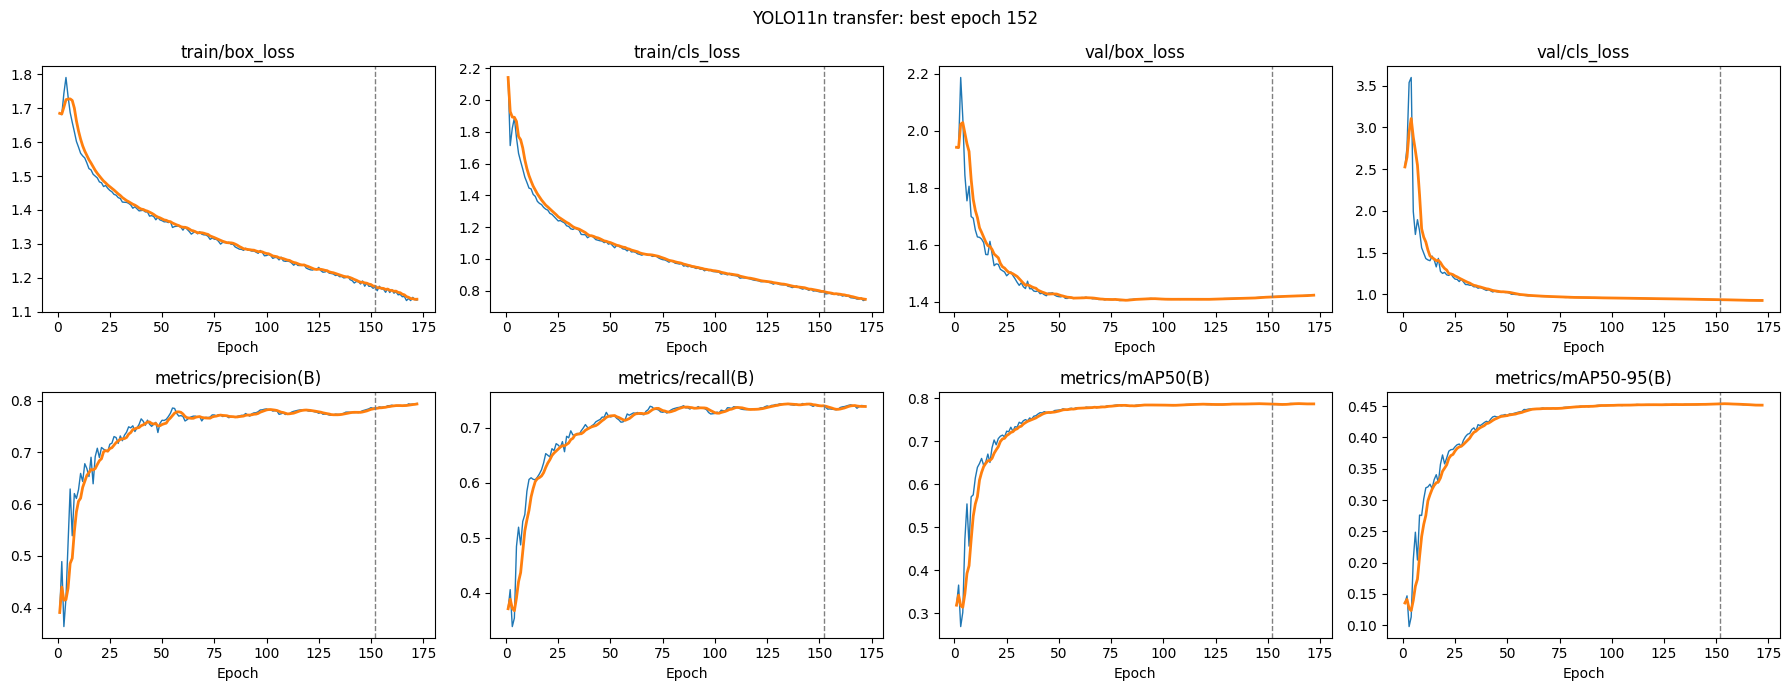

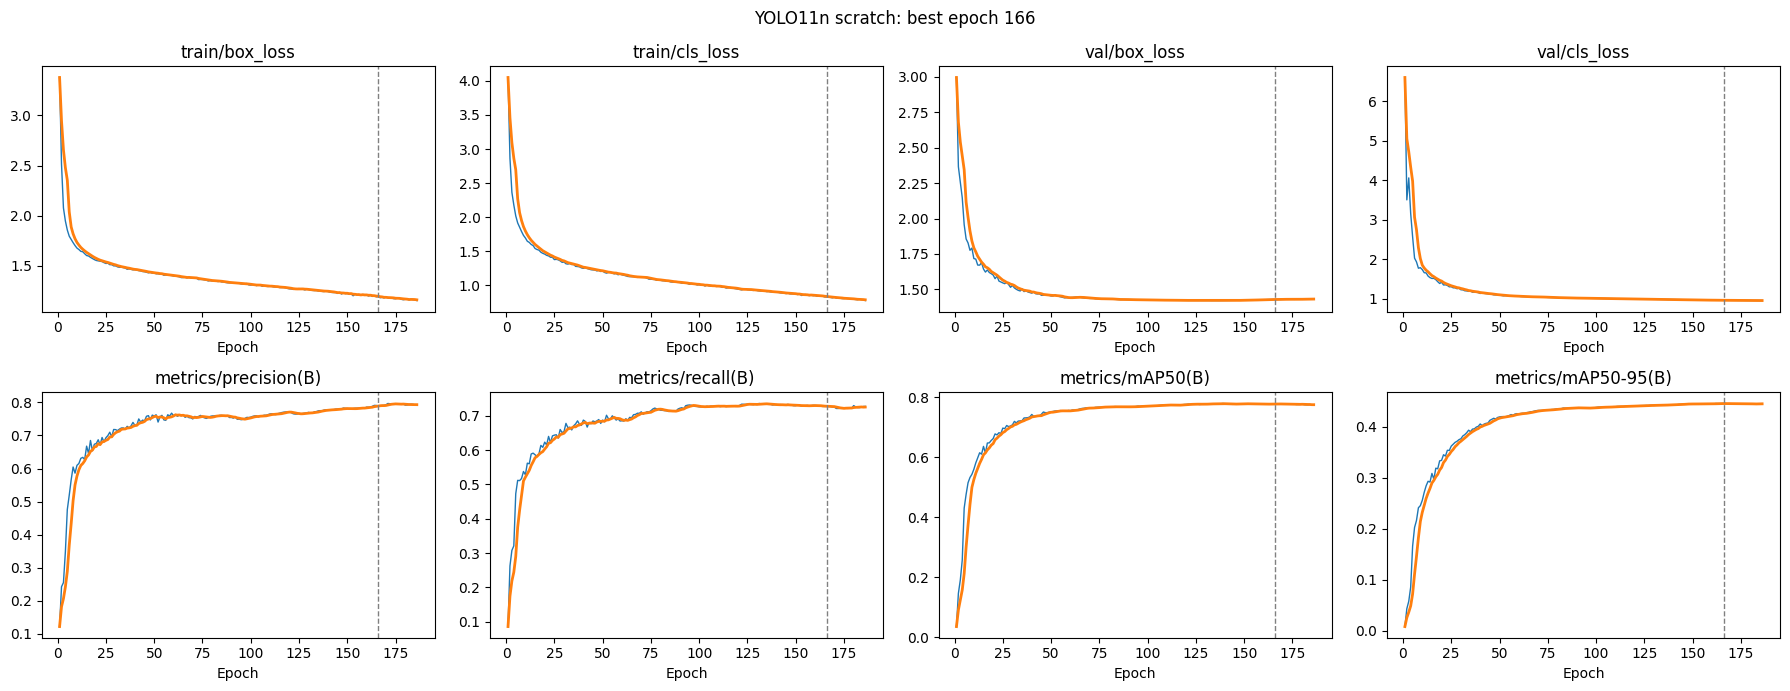

,model,epochs_run,best_epoch,val_mAP50,val_mAP50_95
0,transfer,172,152,0.78602,0.45426
1,scratch,186,166,0.77772,0.44593


In [8]:
def read_history(run_name: str) -> pd.DataFrame:
    history = pd.read_csv(RUN_DIR / run_name / "results.csv")
    history.columns = [column.strip() for column in history.columns]
    history["fitness"] = 0.1 * history["metrics/mAP50(B)"] + 0.9 * history["metrics/mAP50-95(B)"]
    return history


histories = {"transfer": read_history("train")}
if SCRATCH_PT is not None:
    histories["scratch"] = read_history("scratch")
history_rows = []
for name, history in histories.items():
    best_row = history.loc[history["fitness"].idxmax()]
    history_rows.append({"model": name, "epochs_run": len(history), "best_epoch": int(best_row["epoch"]),
                         "val_mAP50": float(best_row["metrics/mAP50(B)"]),
                         "val_mAP50_95": float(best_row["metrics/mAP50-95(B)"])})
    history.to_csv(RUN_DIR / "reports" / f"history_{name}.csv", index=False)
    columns = ["train/box_loss", "train/cls_loss", "val/box_loss", "val/cls_loss",
               "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]
    fig, axes = plt.subplots(2, 4, figsize=(18, 7))
    for axis, column in zip(axes.ravel(), columns):
        axis.plot(history["epoch"], history[column], linewidth=1)
        axis.plot(history["epoch"], history[column].rolling(5, min_periods=1).mean(), linewidth=2)
        axis.axvline(best_row["epoch"], color="gray", linestyle="--", linewidth=1)
        axis.set_title(column)
        axis.set_xlabel("Epoch")
    fig.suptitle(f"YOLO11n {name}: best epoch {int(best_row['epoch'])}")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "reports" / f"training_curves_{name}.png", dpi=150)
    display(fig)
    plt.close(fig)
history_table = pd.DataFrame(history_rows)
history_table.to_csv(RUN_DIR / "reports" / "training_history_summary.csv", index=False)
display(history_table)


## Cùng ảnh val: trước và sau fine-tune

So sánh dự đoán của COCO pretrained với `best.pt` trên đúng các ảnh val đã chọn ở trên. Bảng và ảnh chỉ là minh họa định tính; bằng chứng định lượng cho lợi ích của khởi tạo pretrained cần run scratch.


,image,ground_truth,pretrained_coco_predictions,finetuned_predictions
0,dbafire_dbafire_01653.jpg,fire_only,car,fire
1,dfire_WEB05999.jpg,fire_only,,"fire, fire"
2,dfire_PublicDataset00802.jpg,smoke_only,,smoke
3,dbafire_dbafire_02632.jpg,smoke_only,surfboard,smoke
4,dfire_WEB03851.jpg,both,,"smoke, fire, fire"
5,dfire_WEB06205.jpg,both,person,smoke
6,flame_lake_resized_lake_frame1021.jpg,background,,
7,dfire_WEB02365.jpg,background,,


dbafire_dbafire_01653.jpg — COCO pretrained / FinalSFD fine-tuned


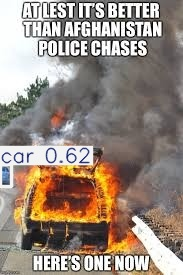

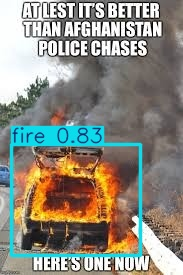

dfire_WEB05999.jpg — COCO pretrained / FinalSFD fine-tuned


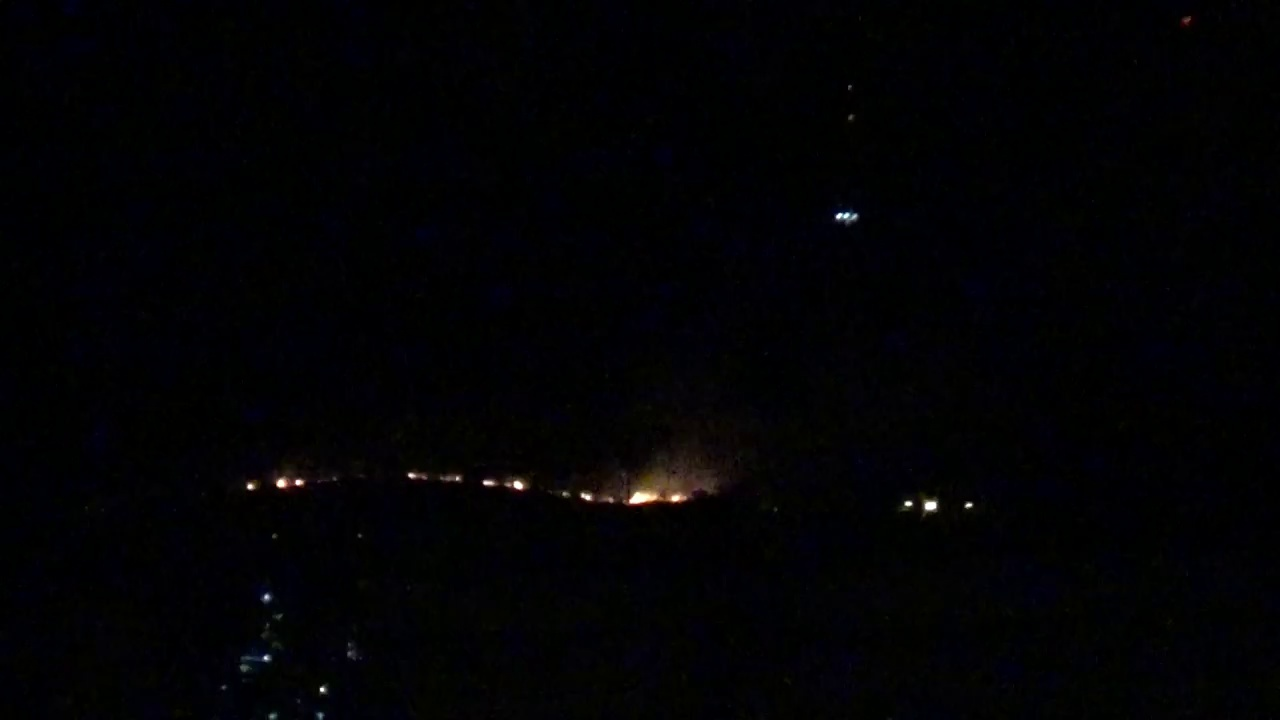

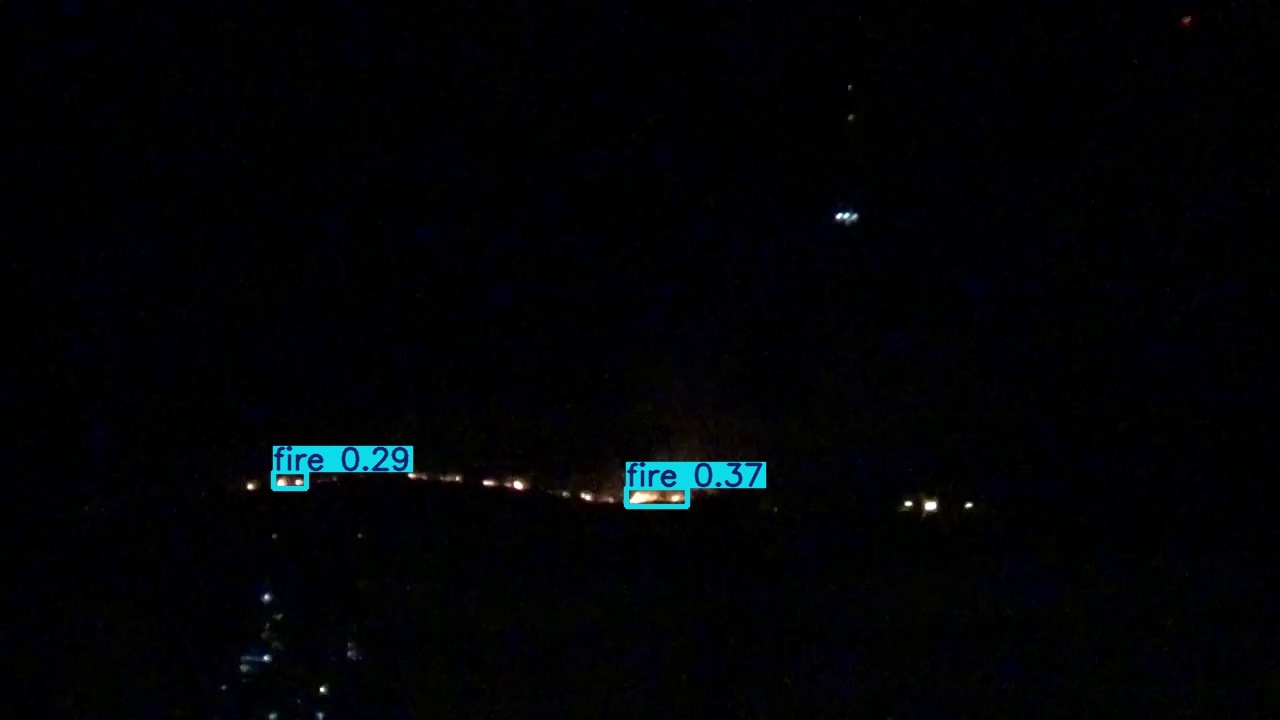

dfire_PublicDataset00802.jpg — COCO pretrained / FinalSFD fine-tuned


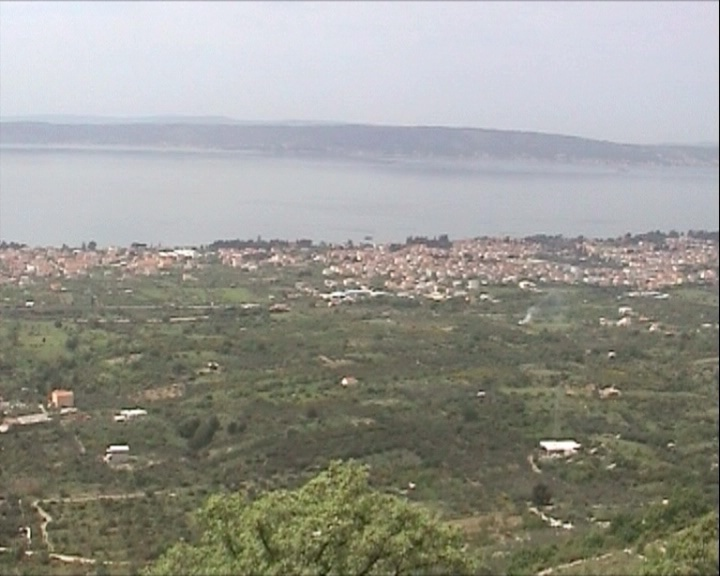

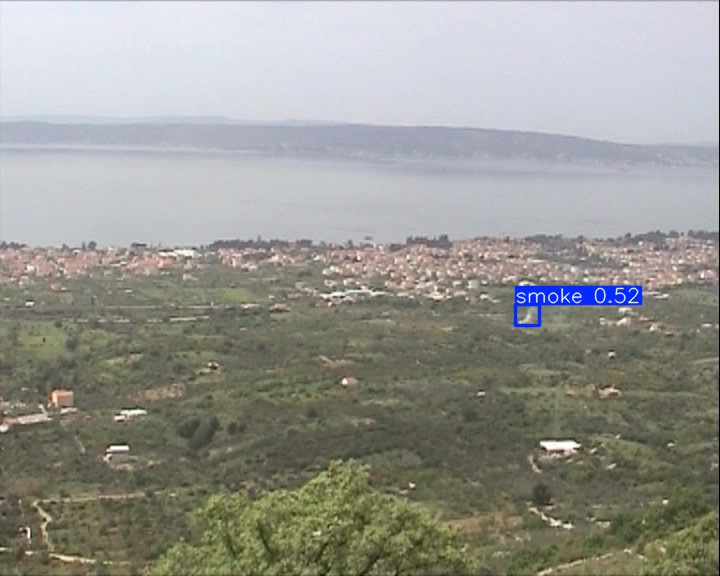

dbafire_dbafire_02632.jpg — COCO pretrained / FinalSFD fine-tuned


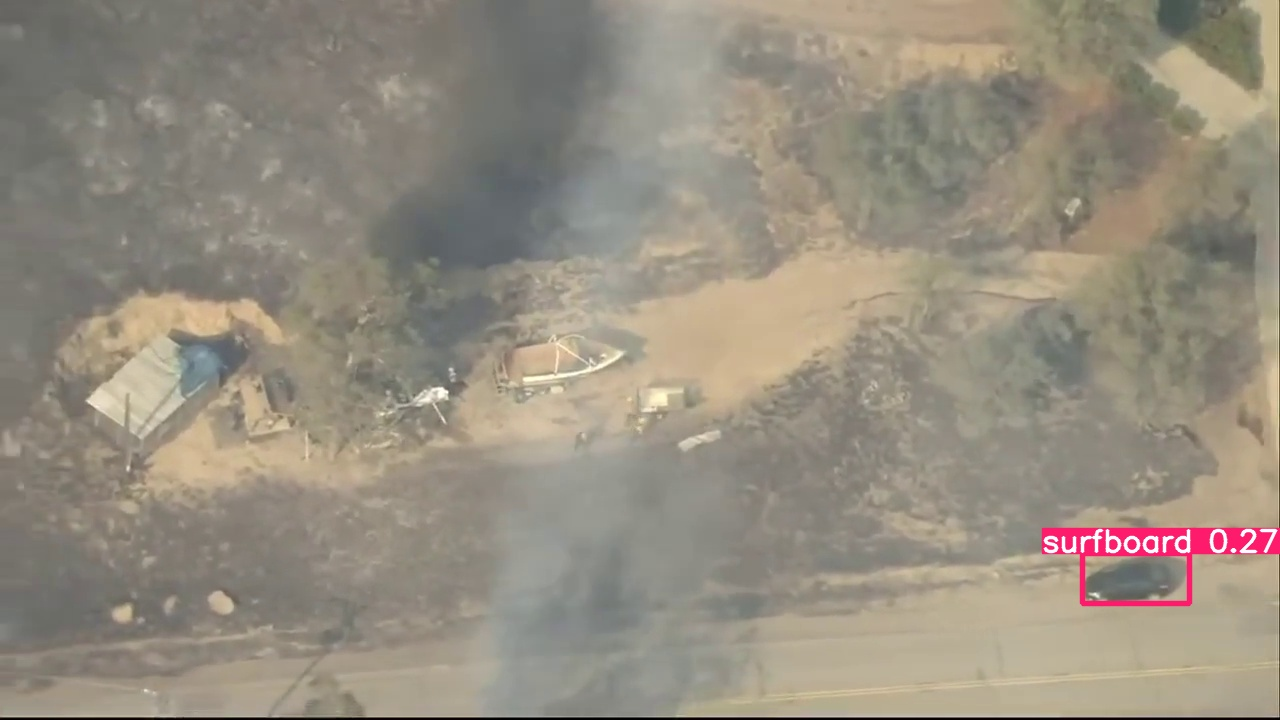

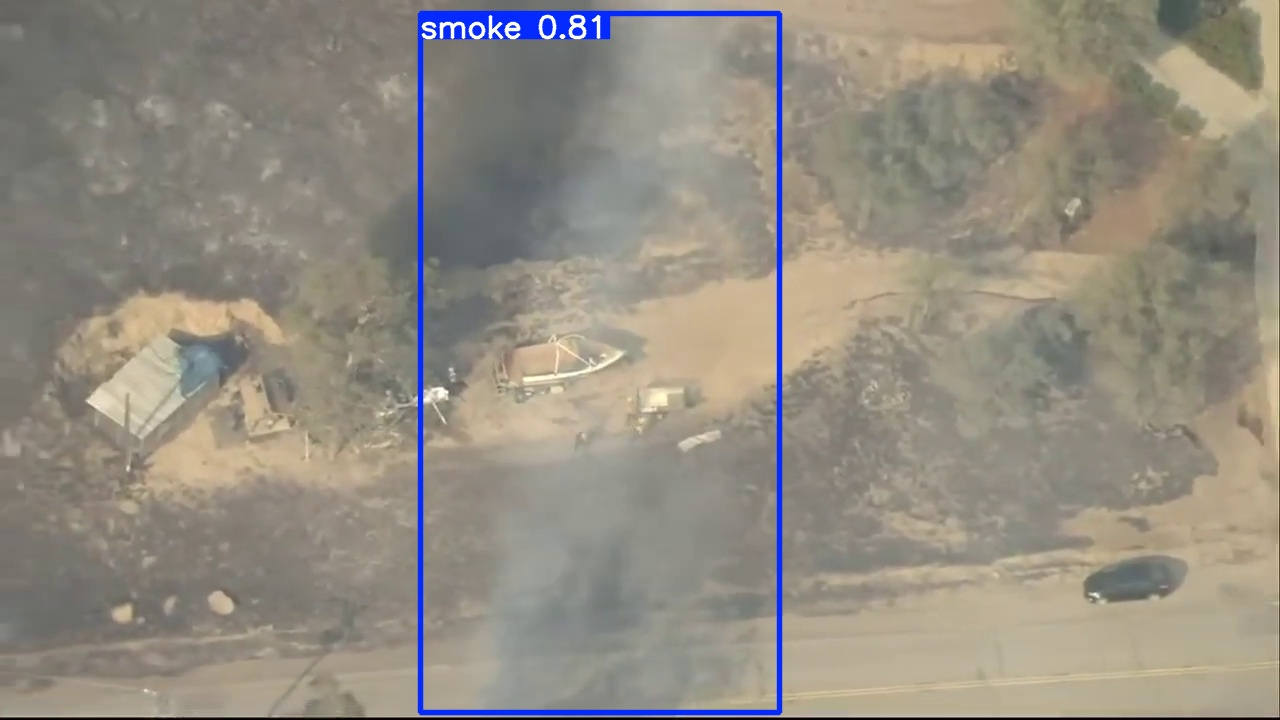

In [9]:
finetuned_model = YOLO(str(BEST_PT))
finetuned_dir = RUN_DIR / "reports" / "finetuned_val_examples"
finetuned_dir.mkdir(parents=True, exist_ok=True)
before_after_rows = []
for earlier, path in zip(pretrained_rows, pretrained_paths):
    result = finetuned_model.predict(path, imgsz=IMAGE_SIZE, conf=VIS_CONF,
                                     iou=NMS_IOU, device="cpu", batch=1, verbose=False)[0]
    predicted_names = [result.names[int(class_id)] for class_id in result.boxes.cls.cpu().tolist()]
    output_path = finetuned_dir / Path(path).name
    result.save(filename=str(output_path))
    before_after_rows.append({"image": Path(path).name,
                              "ground_truth": earlier["true_category"],
                              "pretrained_coco_predictions": earlier["coco_predictions"],
                              "finetuned_predictions": ", ".join(predicted_names)})
    del result
before_after_table = pd.DataFrame(before_after_rows)
before_after_table.to_csv(RUN_DIR / "reports" / "pretrained_vs_finetuned_val.csv", index=False)
display(before_after_table)
for path in pretrained_paths[:4]:
    name = Path(path).name
    print(name, "— COCO pretrained / FinalSFD fine-tuned")
    display(NotebookImage(filename=str(pretrained_dir / name), width=440))
    display(NotebookImage(filename=str(finetuned_dir / name), width=440))
del finetuned_model
gc.collect()
torch.cuda.empty_cache()


## Đánh giá `best.pt` trên val và test

Hai lần đánh giá dùng cùng `imgsz`, `batch`, confidence thấp để tính mAP và NMS IoU. Test chỉ được đọc sau khi `best.pt` đã được chọn bằng val.


Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2881.8±1328.5 MB/s, size: 159.5 KB)
val: Scanning /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/labels/val.cache... 2342 images, 468 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2342/2342 701.6Mit/s 0.0s
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB06626.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB07539.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB07540.jpg: corrupt JPEG restored and saved
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 74/74 4.8it/s 15.4s
                   all       2342       

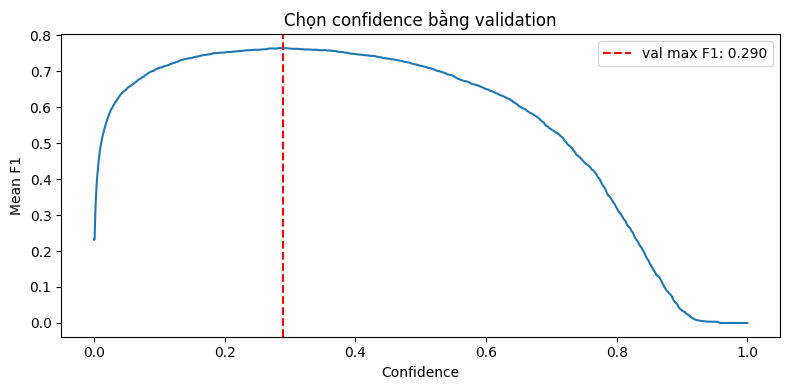

Confidence chọn từ val: 0.29
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1536.3±769.8 MB/s, size: 59.0 KB)
val: Scanning /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/labels/test... 3857 images, 772 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3857/3857 1.2Kit/s 3.3s
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/test/dfire_WEB11243.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/test/dfire_WEB11244.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/test/dfire_WEB11245.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/test/dfire_WEB11313.jpg: corrupt JPEG restored and saved
val: /kaggle

,split,class,precision,recall,mAP50,mAP50_95,F1
0,val,all,0.787233,0.742092,0.786602,0.453947,0.763996
1,val,smoke,0.833604,0.808180,0.842919,0.522872,0.820695
2,val,fire,0.740863,0.676003,0.730284,0.385022,0.706949
3,test,all,0.790959,0.744283,0.797345,0.459455,0.766912
4,test,smoke,0.834874,0.817131,0.858764,0.535044,0.825907
5,test,fire,0.747044,0.671436,0.735925,0.383867,0.707225


In [10]:
# Chỉ đánh giá test sau khi checkpoint đã được chọn bằng validation.
best_model = YOLO(str(BEST_PT))


def summarize_metrics(metrics, split: str) -> dict:
    per_class = []
    for metric_index, class_id in enumerate(metrics.box.ap_class_index):
        precision, recall, map50, map50_95 = metrics.box.class_result(metric_index)
        per_class.append({
            "class_id": int(class_id),
            "class_name": str(metrics.names[int(class_id)]),
            "precision": float(precision),
            "recall": float(recall),
            "mAP50": float(map50),
            "mAP50_95": float(map50_95),
        })
    mean_precision, mean_recall, mean_map50, mean_map50_95 = metrics.box.mean_results()
    return {
        "split": split,
        "overall": {
            "precision": float(mean_precision), "recall": float(mean_recall),
            "mAP50": float(mean_map50), "mAP50_95": float(mean_map50_95),
        },
        "per_class": per_class,
        "validation_conf": EVAL_CONF,
        "nms_iou": NMS_IOU,
    }


evaluation = {}
for split_name, ultralytics_split in (("val", "val"), ("test", "test")):
    metrics = best_model.val(
        data=str(TRAIN_YAML),
        split=ultralytics_split,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        conf=EVAL_CONF,
        iou=NMS_IOU,
        workers=WORKERS,
        device=0,
        plots=True,
        project=str(RUN_DIR),
        name=f"evaluation_{split_name}",
        exist_ok=True,
        verbose=True,
    )
    evaluation[split_name] = summarize_metrics(metrics, split_name)
    if split_name == "val":
        confidence_grid = np.asarray(metrics.box.px, dtype=float)
        mean_f1 = np.asarray(metrics.box.f1_curve, dtype=float).mean(axis=0)
        chosen_index = int(np.nanargmax(mean_f1))
        DEPLOY_CONF = round(float(confidence_grid[chosen_index]), 3)
        fig, axis = plt.subplots(figsize=(8, 4))
        axis.plot(confidence_grid, mean_f1)
        axis.axvline(DEPLOY_CONF, color="red", linestyle="--", label=f"val max F1: {DEPLOY_CONF:.3f}")
        axis.set(xlabel="Confidence", ylabel="Mean F1", title="Chọn confidence bằng validation")
        axis.legend()
        fig.tight_layout()
        fig.savefig(RUN_DIR / "reports" / "validation_confidence_selection.png", dpi=150)
        display(fig)
        plt.close(fig)
        print("Confidence chọn từ val:", DEPLOY_CONF)
    del metrics
    gc.collect()
    torch.cuda.empty_cache()
    (RUN_DIR / "reports" / f"metrics_{split_name}.json").write_text(
        json.dumps(evaluation[split_name], ensure_ascii=False, indent=2), encoding="utf-8"
    )

metric_rows = []
for split_name, report in evaluation.items():
    metric_rows.append({"split": split_name, "class": "all", **report["overall"]})
    metric_rows.extend({"split": split_name, "class": row["class_name"],
                        **{key: row[key] for key in ("precision", "recall", "mAP50", "mAP50_95")}}
                       for row in report["per_class"])
metrics_table = pd.DataFrame(metric_rows)
metrics_table["F1"] = 2 * metrics_table["precision"] * metrics_table["recall"] / (
    metrics_table["precision"] + metrics_table["recall"]
).replace(0, np.nan)
display(metrics_table)
metrics_table.to_csv(RUN_DIR / "reports" / "metrics_comparison.csv", index=False)
# Phần báo cáo ảnh dùng CPU; không giữ model đánh giá trên GPU.
del best_model
gc.collect()
torch.cuda.empty_cache()


## Bảng so sánh transfer và scratch

Nếu đã bật scratch, đánh giá hai checkpoint trên cùng val/test ở `NMS_IOU=0.5`, `conf=0.001`. Nếu chưa chạy scratch thì bảng chỉ ghi transfer và không đưa ra kết luận so sánh.


In [11]:
comparison_rows = []
for split in ("val", "test"):
    comparison_rows.append({"model": "transfer", "split": split, "class": "all",
                            **evaluation[split]["overall"]})
    comparison_rows.extend({"model": "transfer", "split": split, "class": row["class_name"],
                            **{key: row[key] for key in ("precision", "recall", "mAP50", "mAP50_95")}}
                           for row in evaluation[split]["per_class"])
if SCRATCH_PT is not None:
    scratch_eval_model = YOLO(str(SCRATCH_PT))
    for split in ("val", "test"):
        scratch_metrics = scratch_eval_model.val(
            data=str(TRAIN_YAML), split=split, imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
            conf=EVAL_CONF, iou=NMS_IOU, workers=WORKERS, device=0,
            plots=True, project=str(RUN_DIR), name=f"scratch_evaluation_{split}",
            exist_ok=True, verbose=False,
        )
        scratch_report = summarize_metrics(scratch_metrics, split)
        comparison_rows.append({"model": "scratch", "split": split, "class": "all",
                                **scratch_report["overall"]})
        comparison_rows.extend({"model": "scratch", "split": split, "class": row["class_name"],
                                **{key: row[key] for key in ("precision", "recall", "mAP50", "mAP50_95")}}
                               for row in scratch_report["per_class"])
        del scratch_metrics
        gc.collect()
        torch.cuda.empty_cache()
    del scratch_eval_model
    gc.collect()
    torch.cuda.empty_cache()
else:
    print("Chưa chạy scratch; không suy ra ưu thế của transfer learning.")
comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(RUN_DIR / "reports" / "transfer_vs_scratch.csv", index=False)
display(comparison_table)


Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 100 layers, 2,582,542 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2482.4±1366.9 MB/s, size: 177.3 KB)
val: Scanning /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/labels/val.cache... 2342 images, 468 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2342/2342 893.0Mit/s 0.0s
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB06626.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB07539.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB07540.jpg: corrupt JPEG restored and saved
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 74/74 4.9it/s 15.1s
                   all       2342       

,model,split,class,precision,recall,mAP50,mAP50_95
0,transfer,val,all,0.787233,0.742092,0.786602,0.453947
1,transfer,val,smoke,0.833604,0.808180,0.842919,0.522872
2,transfer,val,fire,0.740863,0.676003,0.730284,0.385022
3,transfer,test,all,0.790959,0.744283,0.797345,0.459455
4,transfer,test,smoke,0.834874,0.817131,0.858764,0.535044
5,transfer,test,fire,0.747044,0.671436,0.735925,0.383867
6,scratch,val,all,0.791446,0.729582,0.778321,0.446015
7,scratch,val,smoke,0.841691,0.788594,0.834584,0.518177
8,scratch,val,fire,0.741202,0.670569,0.722057,0.373853
9,scratch,test,all,0.782817,0.739836,0.783138,0.448042


## Khảo sát ngưỡng NMS IoU

Giữ nguyên checkpoint, `imgsz=640` và `conf=0.001` để tính mAP; chỉ thay NMS IoU. Bảng val dùng để biện minh cho cấu hình chính 0.5; test chỉ kiểm tra độ nhạy sau khi đã cố định cấu hình. Một mẫu val gồm ảnh nền và ảnh có cả hai lớp được dự đoán ở confidence triển khai để quan sát báo nhầm và số box.


Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2655.9±2151.9 MB/s, size: 168.2 KB)
val: Scanning /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/labels/val.cache... 2342 images, 468 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2342/2342 755.6Mit/s 0.0s
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB06626.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB07539.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB07540.jpg: corrupt JPEG restored and saved
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 74/74 5.6it/s 13.2s
                   all       2342       

,split,nms_iou,class,precision,recall,mAP50,mAP50_95
0,val,0.3,all,0.789668,0.739633,0.765764,0.441452
1,val,0.3,smoke,0.836301,0.804724,0.819876,0.509439
2,val,0.3,fire,0.743035,0.674542,0.711653,0.373465
3,val,0.5,all,0.787233,0.742092,0.786602,0.453947
4,val,0.5,smoke,0.833604,0.808180,0.842919,0.522872
5,val,0.5,fire,0.740863,0.676003,0.730284,0.385022
6,val,0.7,all,0.776082,0.728748,0.781259,0.459983
7,val,0.7,smoke,0.819283,0.799108,0.840293,0.530602
8,val,0.7,fire,0.732882,0.658387,0.722224,0.389364
9,val,0.9,all,0.729208,0.641968,0.707502,0.435317


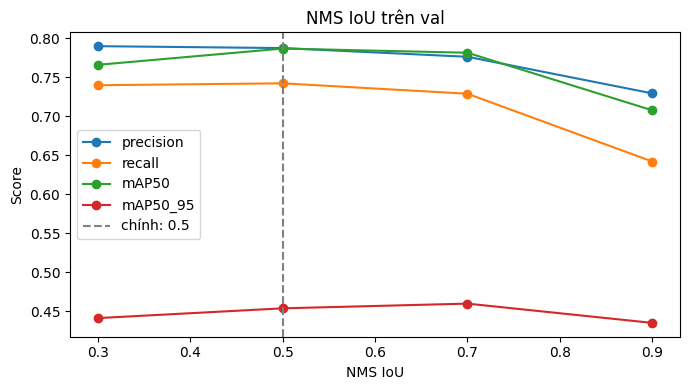

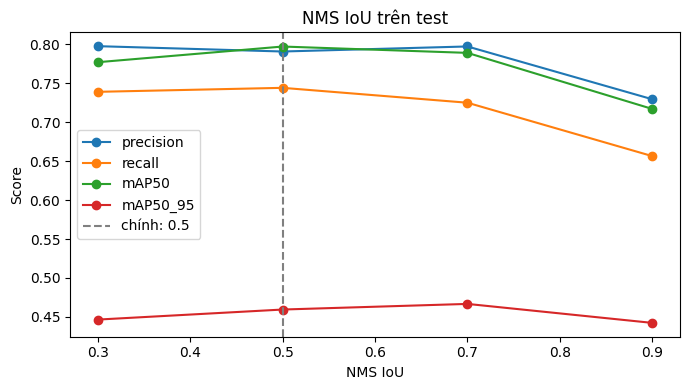

,nms_iou,category,confidence,images,images_with_detection,detections
0,0.3,background,0.29,80,1,1
1,0.3,both,0.29,80,80,253
2,0.5,background,0.29,80,1,1
3,0.5,both,0.29,80,80,255
4,0.7,background,0.29,80,1,1
5,0.7,both,0.29,80,80,261
6,0.9,background,0.29,80,1,1
7,0.9,both,0.29,80,80,385


In [12]:
iou_rows = []
sweep_model = YOLO(str(BEST_PT))
for split in ("val", "test"):
    for nms_iou in IOU_SWEEP:
        sweep_metrics = sweep_model.val(
            data=str(TRAIN_YAML), split=split, imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
            conf=EVAL_CONF, iou=nms_iou, workers=WORKERS, device=0,
            plots=False, project=str(RUN_DIR), name=f"nms_{split}_{nms_iou:.1f}",
            exist_ok=True, verbose=False,
        )
        report = summarize_metrics(sweep_metrics, split)
        rows = [("all", report["overall"])] + [
            (row["class_name"], {key: row[key] for key in ("precision", "recall", "mAP50", "mAP50_95")})
            for row in report["per_class"]
        ]
        for class_name, values in rows:
            iou_rows.append({"split": split, "nms_iou": nms_iou, "class": class_name, **values})
        del sweep_metrics
        gc.collect()
        torch.cuda.empty_cache()
iou_table = pd.DataFrame(iou_rows)
iou_table.to_csv(RUN_DIR / "reports" / "nms_iou_sweep.csv", index=False)
display(iou_table)
for split in ("val", "test"):
    subset = iou_table[(iou_table["split"] == split) & (iou_table["class"] == "all")]
    fig, axis = plt.subplots(figsize=(7, 4))
    for metric in ("precision", "recall", "mAP50", "mAP50_95"):
        axis.plot(subset["nms_iou"], subset[metric], marker="o", label=metric)
    axis.axvline(NMS_IOU, color="gray", linestyle="--", label="chính: 0.5")
    axis.set(xlabel="NMS IoU", ylabel="Score", title=f"NMS IoU trên {split}")
    axis.legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / "reports" / f"nms_iou_sweep_{split}.png", dpi=150)
    display(fig)
    plt.close(fig)

val_background = sorted(val_records.loc[val_records["category"] == "background", "image"].tolist())
val_both = sorted(val_records.loc[val_records["category"] == "both", "image"].tolist())
probe_rng = random.Random(SEED)
probe_groups = {
    "background": probe_rng.sample(val_background, min(80, len(val_background))),
    "both": probe_rng.sample(val_both, min(80, len(val_both))),
}
operational_rows = []
for nms_iou in IOU_SWEEP:
    for category, paths in probe_groups.items():
        detections, images_with_detection = 0, 0
        for path in paths:
            result = sweep_model.predict(path, conf=DEPLOY_CONF, iou=nms_iou,
                                         imgsz=IMAGE_SIZE, batch=1, device="cpu", verbose=False)[0]
            count = len(result.boxes)
            detections += count
            images_with_detection += int(count > 0)
            del result
        operational_rows.append({"nms_iou": nms_iou, "category": category,
                                 "confidence": DEPLOY_CONF, "images": len(paths),
                                 "images_with_detection": images_with_detection,
                                 "detections": detections})
operational_table = pd.DataFrame(operational_rows)
operational_table.to_csv(RUN_DIR / "reports" / "nms_iou_operational_val.csv", index=False)
display(operational_table)
del sweep_model
gc.collect()
torch.cuda.empty_cache()


## Ma trận nhầm lẫn ở confidence triển khai

Đánh giá thêm val/test với confidence đã chọn từ val và NMS IoU chính 0.5 để tạo ma trận nhầm lẫn gần với lúc dự đoán. Không dùng mAP từ lần lọc confidence cao này làm mAP chuẩn; mAP chuẩn ở phần `conf=0.001`. Bảng mức ảnh ở phần kế tiếp phản ánh trực tiếp ngưỡng triển khai.


Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1268.1±668.5 MB/s, size: 52.4 KB)
val: Scanning /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/labels/val.cache... 2342 images, 468 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2342/2342 755.6Mit/s 0.0s
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB06626.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB07539.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/val/dfire_WEB07540.jpg: corrupt JPEG restored and saved
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 74/74 5.0it/s 14.7s
                   all       2342       41

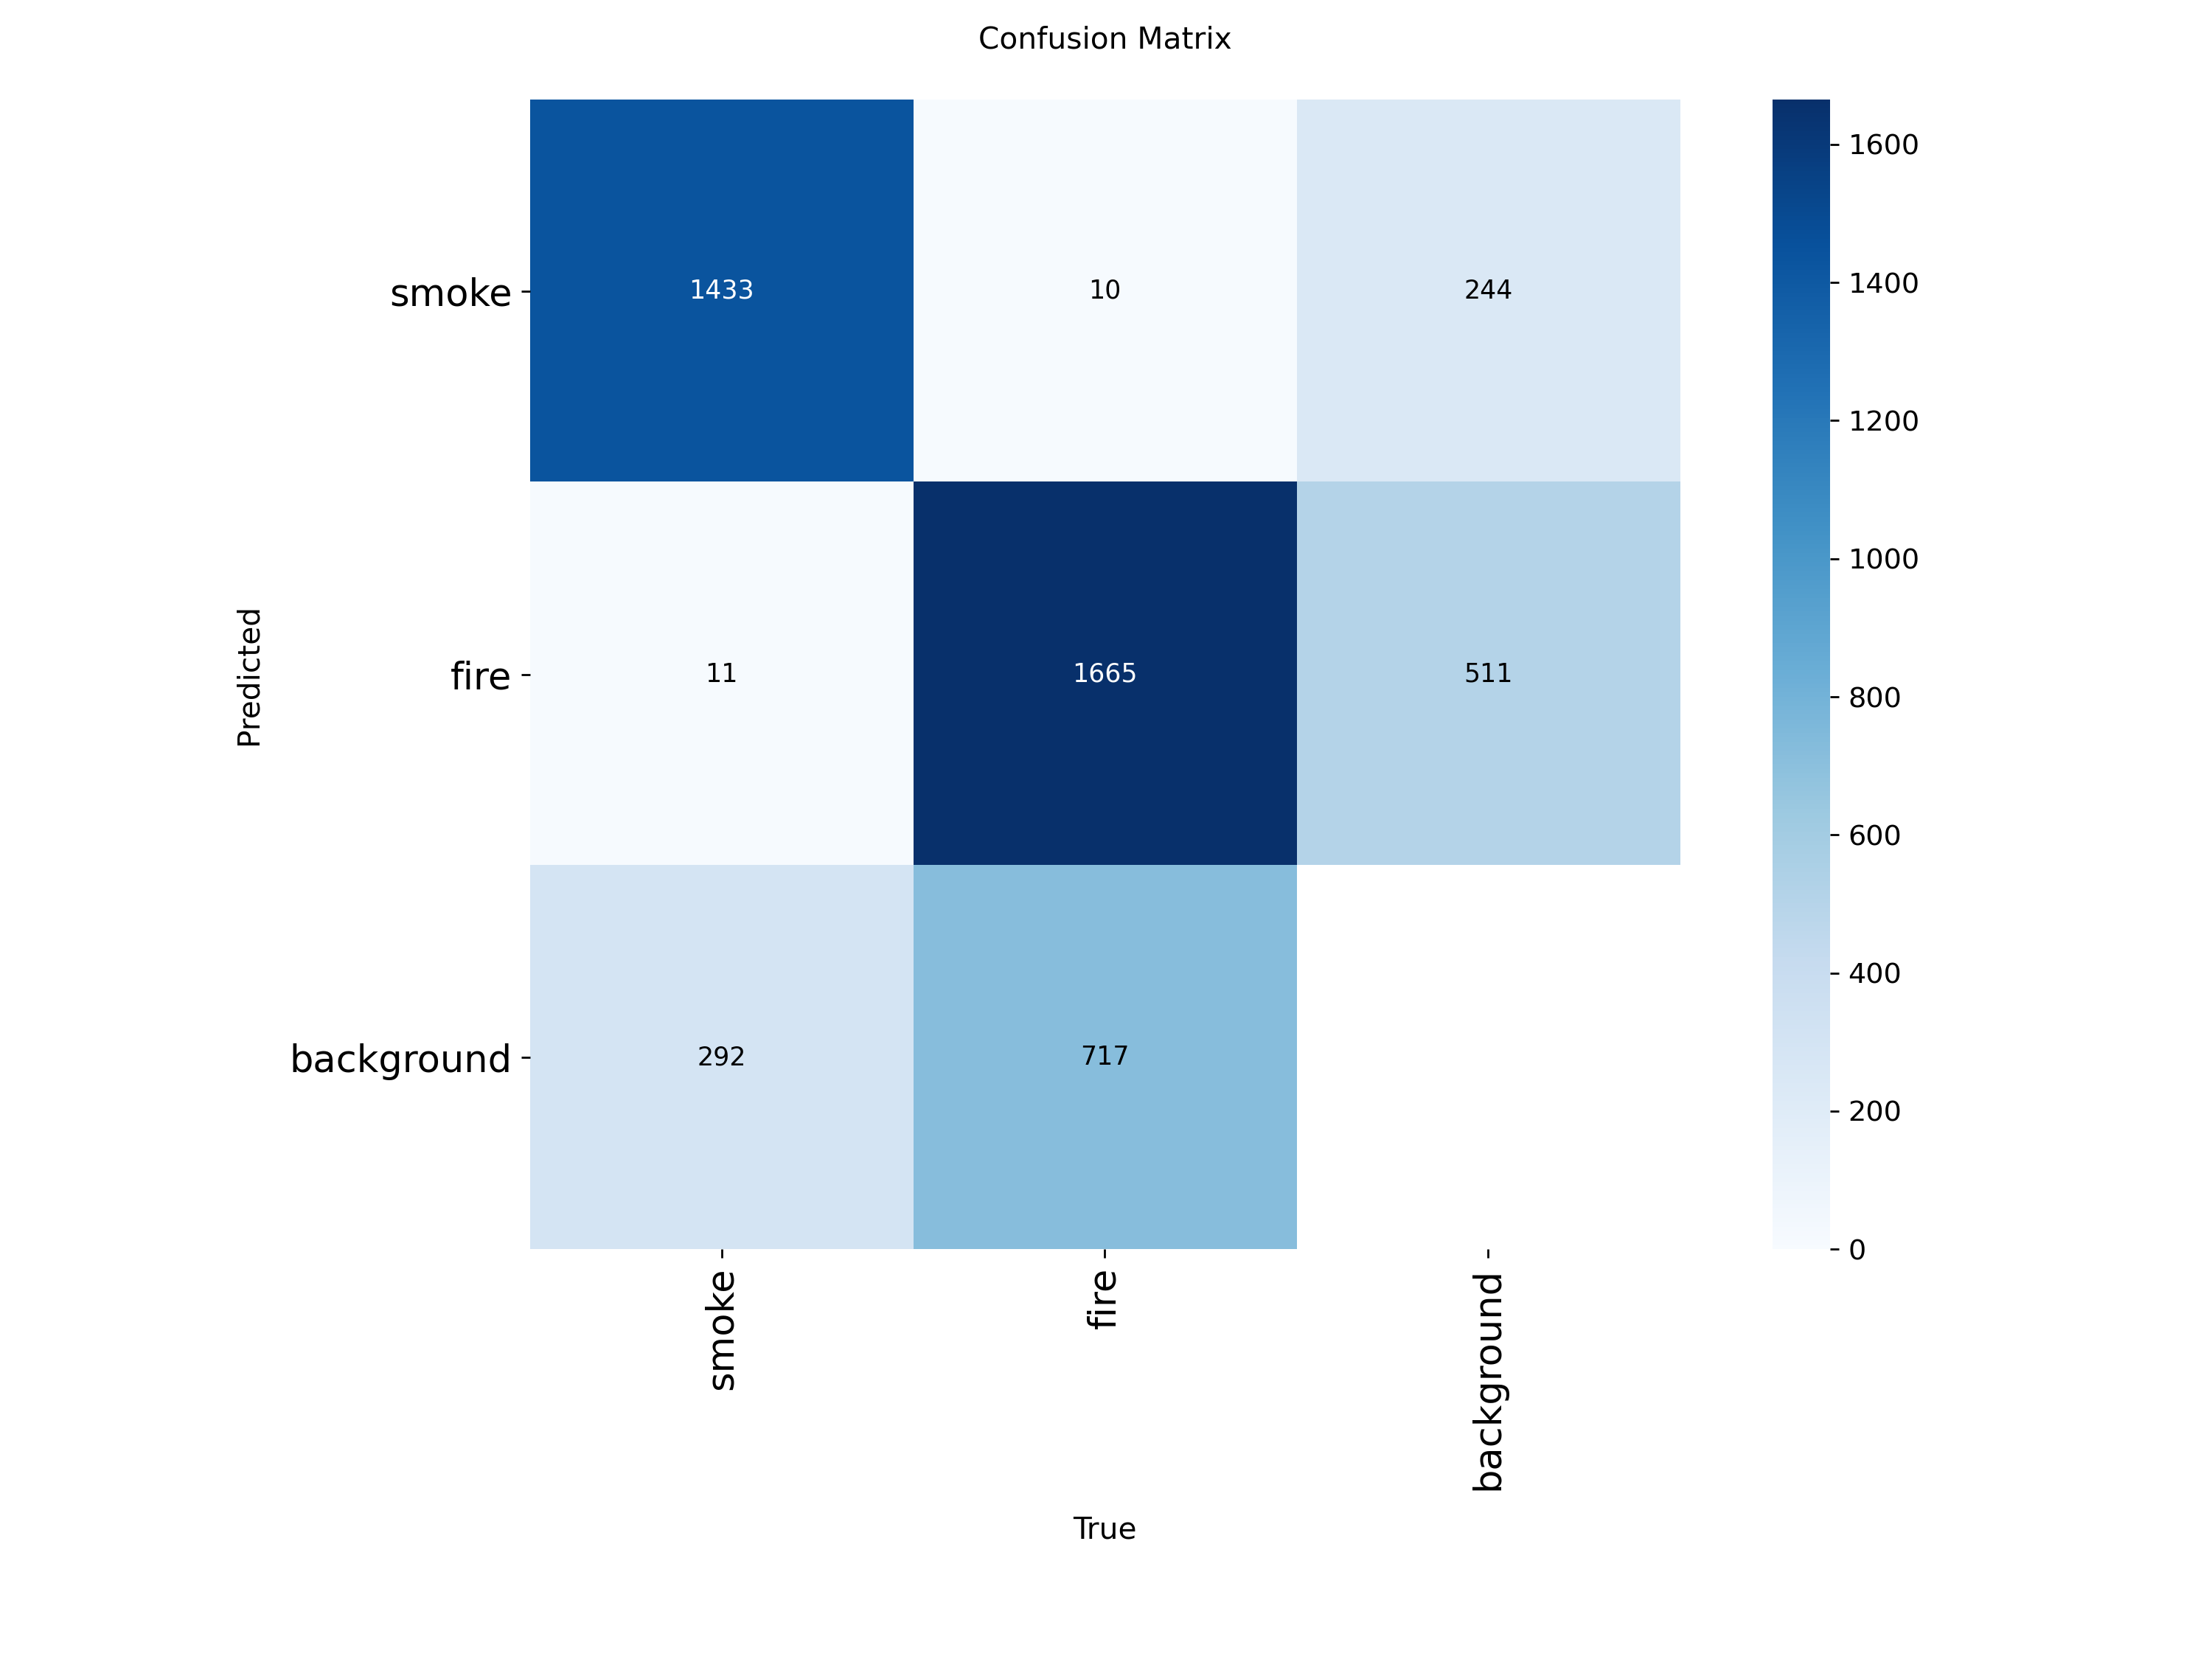

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2348.0±1357.5 MB/s, size: 176.8 KB)
val: Scanning /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/labels/test.cache... 3857 images, 772 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3857/3857 1.2Git/s 0.0s
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/test/dfire_WEB11243.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/test/dfire_WEB11244.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/test/dfire_WEB11245.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yolo11n_20261112_170520/dataset_local/images/test/dfire_WEB11313.jpg: corrupt JPEG restored and saved
val: /kaggle/working/final_sfd_yo

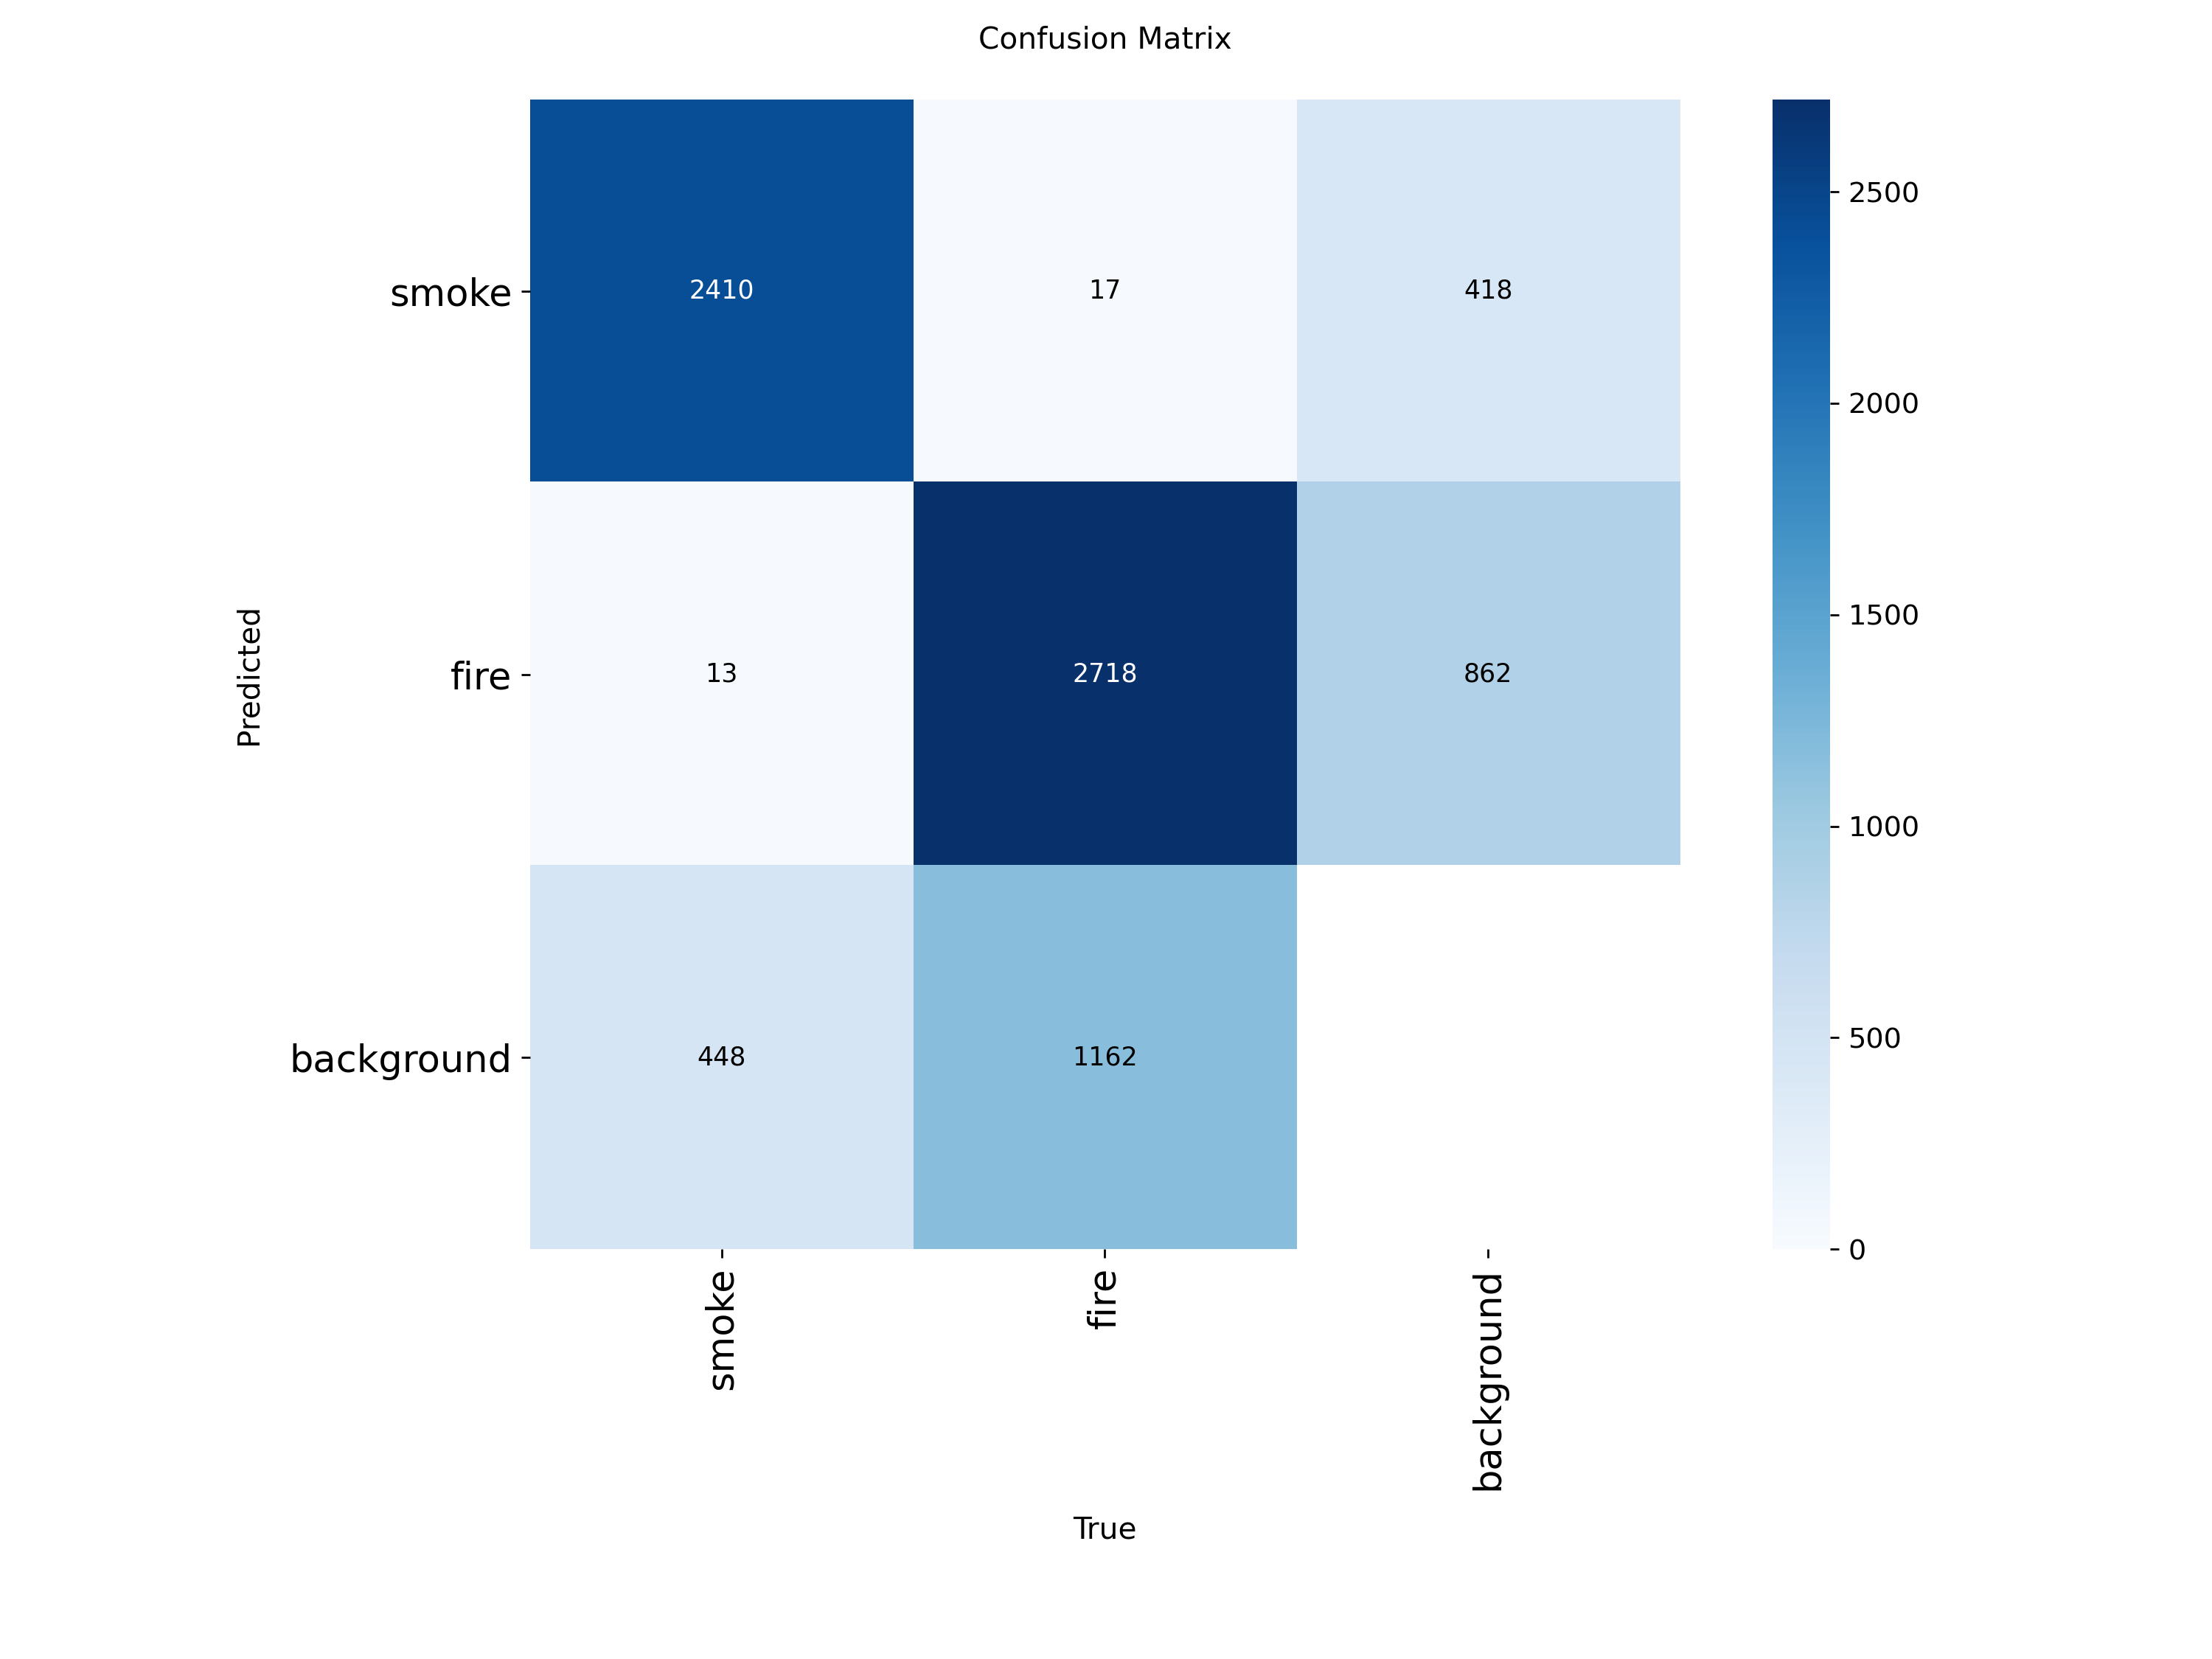

In [13]:
operational_model = YOLO(str(BEST_PT))
for split in ("val", "test"):
    operational_metrics = operational_model.val(
        data=str(TRAIN_YAML), split=split, imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
        conf=DEPLOY_CONF, iou=NMS_IOU, workers=WORKERS, device=0,
        plots=True, project=str(RUN_DIR), name=f"evaluation_{split}_deploy",
        exist_ok=True, verbose=False,
    )
    matrix_path = Path(operational_metrics.save_dir) / "confusion_matrix.png"
    if matrix_path.is_file():
        print(f"Ma trận {split} tại conf={DEPLOY_CONF}, NMS IoU={NMS_IOU}")
        display(NotebookImage(filename=str(matrix_path), width=700))
    del operational_metrics
    gc.collect()
    torch.cuda.empty_cache()
del operational_model
gc.collect()
torch.cuda.empty_cache()


## Đánh giá toàn bộ test ở mức ảnh và kích thước box

Dự đoán từng ảnh trên CPU với confidence đã chọn từ val. Bảng mức ảnh trả lời ảnh có lửa/khói có được phát hiện không; bảng box theo diện tích dùng ngưỡng diện tích chuẩn hóa riêng của FinalSFD và IoU khớp box 0.5. Danh sách lỗi và ảnh minh họa giúp rà lại cả ảnh nền có nhãn gây tranh cãi.


Đã dự đoán test: 200/3857
Đã dự đoán test: 400/3857
Đã dự đoán test: 600/3857
Đã dự đoán test: 800/3857
Đã dự đoán test: 1000/3857
Đã dự đoán test: 1200/3857
Đã dự đoán test: 1400/3857
Đã dự đoán test: 1600/3857
Đã dự đoán test: 1800/3857
Đã dự đoán test: 2000/3857
Đã dự đoán test: 2200/3857
Đã dự đoán test: 2400/3857
Đã dự đoán test: 2600/3857
Đã dự đoán test: 2800/3857
Đã dự đoán test: 3000/3857
Đã dự đoán test: 3200/3857
Đã dự đoán test: 3400/3857
Đã dự đoán test: 3600/3857
Đã dự đoán test: 3800/3857
Đã dự đoán test: 3857/3857


,class,TP,FP,FN,TN,precision,recall,F1
0,fire,1656,37,102,2062,0.978145,0.941980,0.959722
1,smoke,2263,187,175,1232,0.923673,0.928220,0.925941
2,any,2965,54,120,718,0.982113,0.961102,0.971494


,class,size_group,ground_truth_boxes,matched_boxes,recall_at_conf_iou05
0,smoke,<1%,498,336,0.674699
1,smoke,1–10%,717,535,0.746165
2,smoke,≥10%,1656,1482,0.894928
3,fire,<1%,2127,1225,0.575929
4,fire,1–10%,1256,936,0.745223
5,fire,≥10%,514,417,0.811284


,split,confidence,nms_iou,device,batch,background_images,images_with_detection,image_false_positive_rate
0,test,0.29,0.5,cpu,1,772,54,0.069948


,images
background_false_alarm,54
missed_fire,102
missed_smoke,175


,image,ground_truth_category,detections,annotated_file
0,dbafire_dbafire_01973.jpg,fire_only,1,dbafire_dbafire_01973.jpg
1,dfire_AoF07745.jpg,fire_only,2,dfire_AoF07745.jpg
2,dbafire_dbafire_02873.jpg,smoke_only,1,dbafire_dbafire_02873.jpg
3,dfire_AoF08357.jpg,smoke_only,1,dfire_AoF08357.jpg
4,dfire_WEB11617.jpg,both,2,dfire_WEB11617.jpg
5,dfire_WEB11439.jpg,both,2,dfire_WEB11439.jpg
6,flame_resized_test_nofire_frame114.jpg,background,0,flame_resized_test_nofire_frame114.jpg
7,dfire_WEB09977.jpg,background,1,dfire_WEB09977.jpg
8,dfire_WEB11009.jpg,both,1,dfire_WEB11009.jpg
9,dfire_WEB10041.jpg,fire_only,0,dfire_WEB10041.jpg


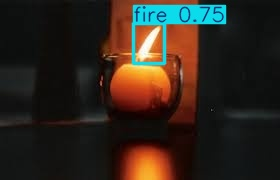

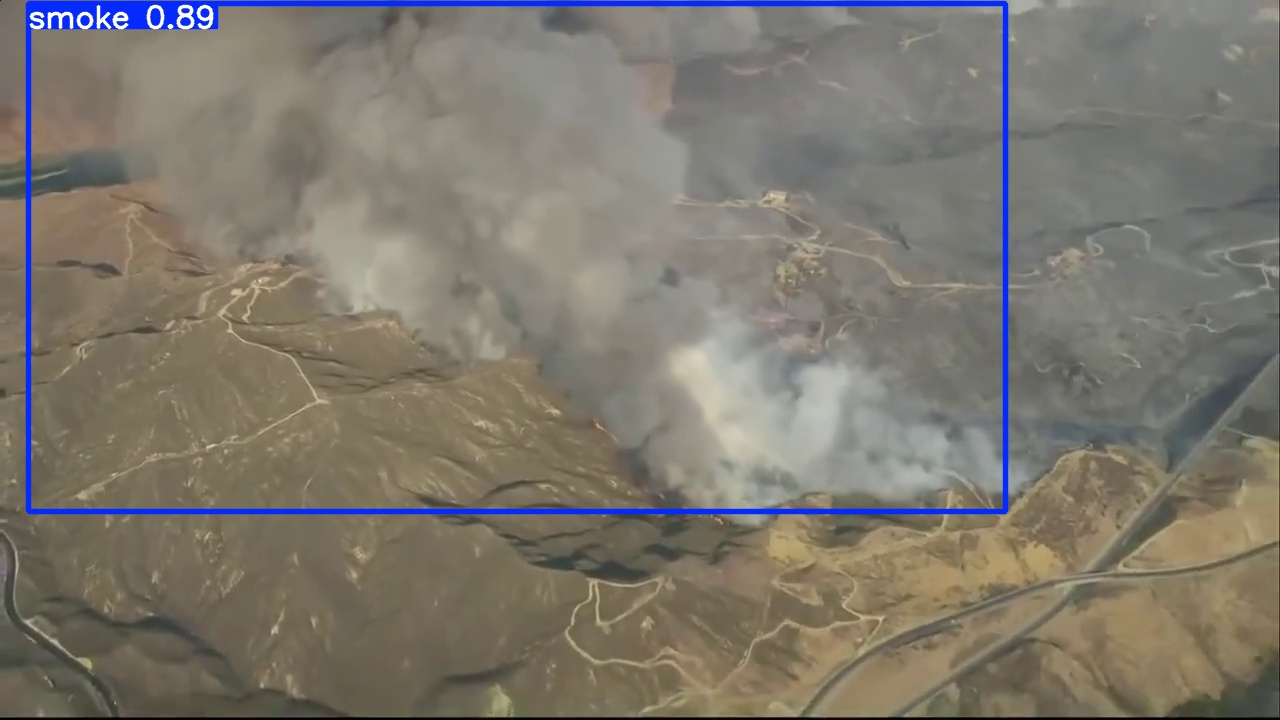

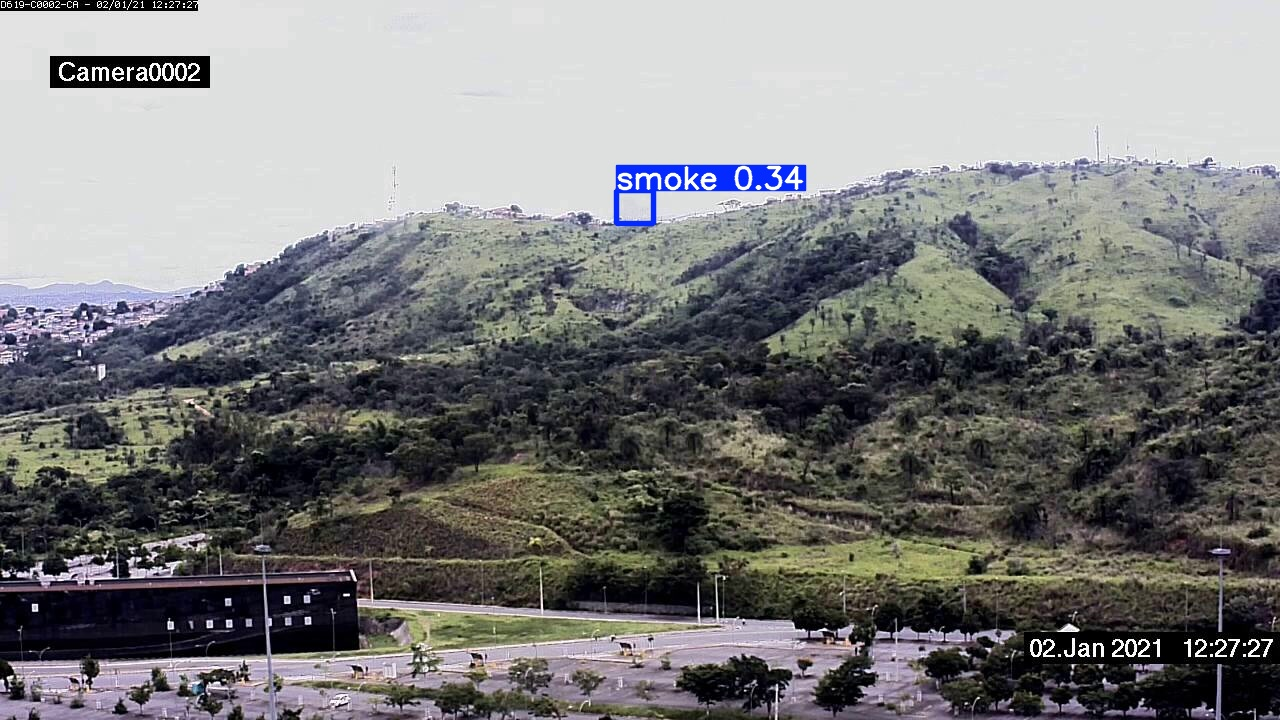

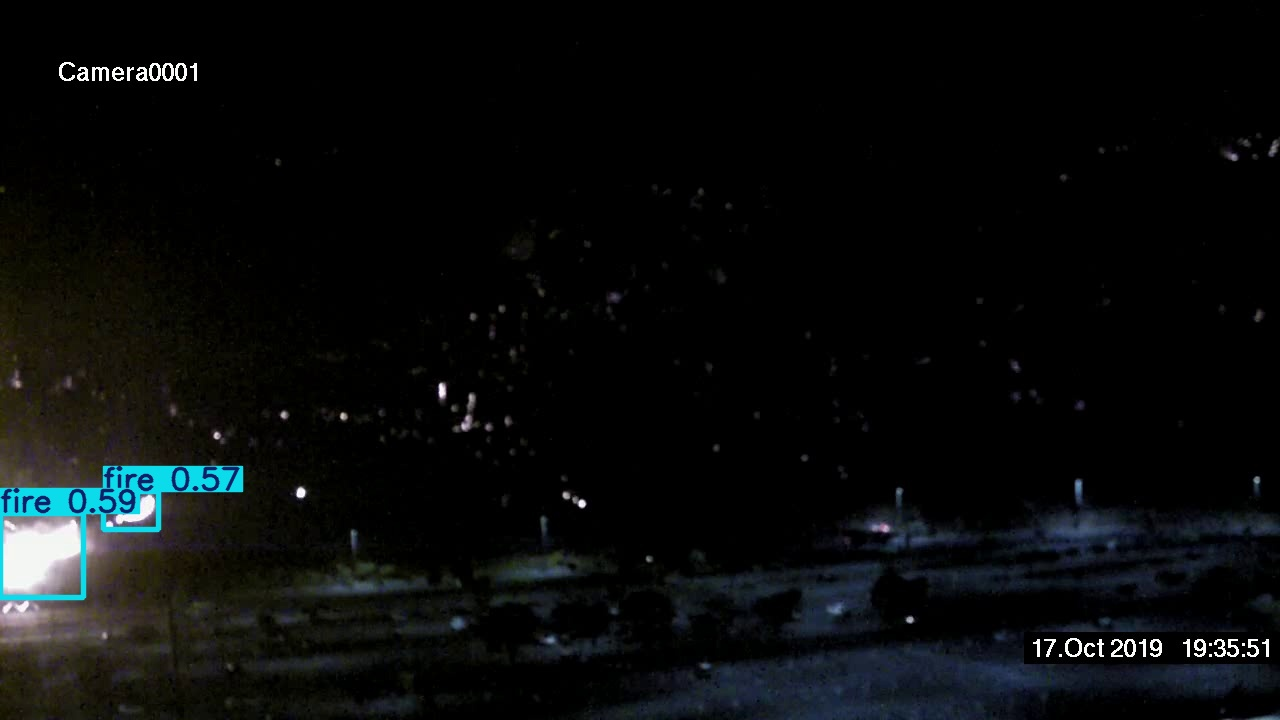

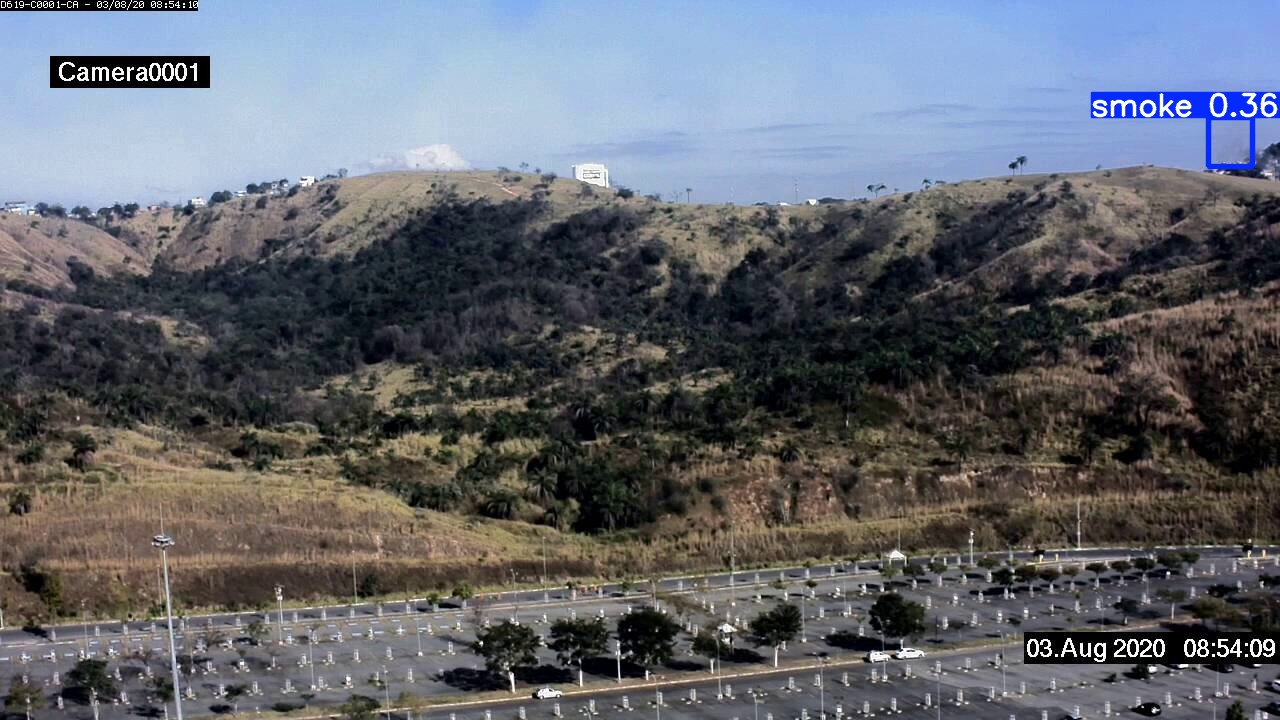

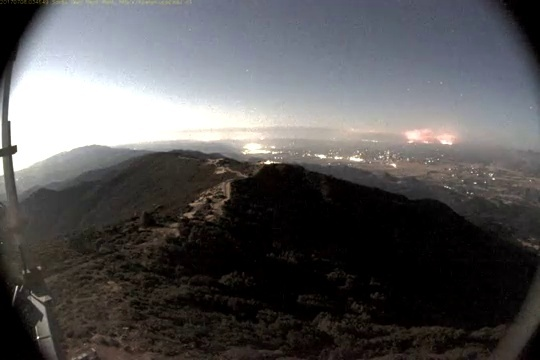

2838

In [14]:
test_records = image_records[image_records["split"] == "test"].reset_index(drop=True)
REPORT_DEVICE = "cpu"
REPORT_BATCH_SIZE = 1
report_model = YOLO(str(BEST_PT))


def predict_one(path: str):
    return report_model.predict(path, batch=REPORT_BATCH_SIZE, conf=DEPLOY_CONF,
                                iou=NMS_IOU, imgsz=IMAGE_SIZE, device=REPORT_DEVICE,
                                verbose=False)[0]


def pair_iou(box, others):
    if len(others) == 0:
        return np.empty(0, dtype=float)
    left_top = np.maximum(box[:2], others[:, :2])
    right_bottom = np.minimum(box[2:], others[:, 2:])
    intersection = np.prod(np.maximum(right_bottom - left_top, 0), axis=1)
    box_area = max(0, box[2] - box[0]) * max(0, box[3] - box[1])
    other_areas = np.maximum(others[:, 2] - others[:, 0], 0) * np.maximum(others[:, 3] - others[:, 1], 0)
    return intersection / np.maximum(box_area + other_areas - intersection, 1e-12)


prediction_rows = []
size_counts = Counter()
for index, row in enumerate(test_records.itertuples(index=False), 1):
    result = predict_one(row.image)
    classes = result.boxes.cls.cpu().numpy().astype(int)
    scores = result.boxes.conf.cpu().numpy()
    boxes = result.boxes.xyxy.cpu().numpy()
    truth_fire = row.category in ("fire_only", "both")
    truth_smoke = row.category in ("smoke_only", "both")
    prediction_rows.append({
        "image": Path(row.image).name, "path": row.image, "category": row.category,
        "true_fire": truth_fire, "true_smoke": truth_smoke,
        "pred_fire": bool(np.any(classes == 1)), "pred_smoke": bool(np.any(classes == 0)),
        "detections": len(classes), "fire_detections": int(np.sum(classes == 1)),
        "smoke_detections": int(np.sum(classes == 0)),
        "max_confidence": float(scores.max()) if len(scores) else 0.0,
    })

    height, width = result.orig_shape
    label_path = LOCAL_DATASET_ROOT / "labels" / "test" / (Path(row.image).stem + ".txt")
    ground_truth = []
    for line in label_path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        class_id, x, y, box_w, box_h = map(float, line.split())
        area = box_w * box_h
        size_group = "<1%" if area < 0.01 else "1–10%" if area < 0.10 else "≥10%"
        ground_truth.append({
            "class_id": int(class_id), "size_group": size_group,
            "box": np.array([(x - box_w / 2) * width, (y - box_h / 2) * height,
                             (x + box_w / 2) * width, (y + box_h / 2) * height]),
        })
    matched_gt = set()
    for pred_index in np.argsort(-scores):
        eligible = [gt_index for gt_index, gt in enumerate(ground_truth)
                    if gt["class_id"] == classes[pred_index] and gt_index not in matched_gt]
        if not eligible:
            continue
        overlaps = pair_iou(boxes[pred_index], np.stack([ground_truth[gt_index]["box"] for gt_index in eligible]))
        best_local = int(np.argmax(overlaps))
        if overlaps[best_local] >= 0.5:
            matched_gt.add(eligible[best_local])
    for gt_index, gt in enumerate(ground_truth):
        key = ("smoke" if gt["class_id"] == 0 else "fire", gt["size_group"])
        size_counts[(key, "ground_truth")] += 1
        size_counts[(key, "matched")] += int(gt_index in matched_gt)
    del result
    if index % 200 == 0 or index == len(test_records):
        print(f"Đã dự đoán test: {index}/{len(test_records)}")

pred_df = pd.DataFrame(prediction_rows)
pred_df.to_csv(RUN_DIR / "reports" / "test_image_predictions.csv", index=False)


def image_level_metrics(actual: pd.Series, predicted: pd.Series) -> dict:
    actual, predicted = actual.astype(bool), predicted.astype(bool)
    tp = int((actual & predicted).sum())
    fp = int((~actual & predicted).sum())
    fn = int((actual & ~predicted).sum())
    tn = int((~actual & ~predicted).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": precision, "recall": recall,
            "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0}


image_metric_rows = []
for class_name, actual, predicted in (
    ("fire", pred_df["true_fire"], pred_df["pred_fire"]),
    ("smoke", pred_df["true_smoke"], pred_df["pred_smoke"]),
    ("any", pred_df["true_fire"] | pred_df["true_smoke"],
     pred_df["pred_fire"] | pred_df["pred_smoke"]),
):
    image_metric_rows.append({"class": class_name, **image_level_metrics(actual, predicted)})
image_metric_table = pd.DataFrame(image_metric_rows)
image_metric_table.to_csv(RUN_DIR / "reports" / "test_image_metrics.csv", index=False)
display(image_metric_table)

size_rows = []
for class_name in ("smoke", "fire"):
    for size_group in ("<1%", "1–10%", "≥10%"):
        key = (class_name, size_group)
        total = size_counts[(key, "ground_truth")]
        matched = size_counts[(key, "matched")]
        size_rows.append({"class": class_name, "size_group": size_group,
                          "ground_truth_boxes": total, "matched_boxes": matched,
                          "recall_at_conf_iou05": matched / total if total else None})
size_recall_table = pd.DataFrame(size_rows)
size_recall_table.to_csv(RUN_DIR / "reports" / "test_box_recall_by_size.csv", index=False)
display(size_recall_table)

background_table = pred_df[pred_df["category"] == "background"].copy()
background_table[["image", "detections", "fire_detections", "smoke_detections", "max_confidence"]].to_csv(
    RUN_DIR / "reports" / "background_test_predictions.csv", index=False
)
background_false_positive_images = int((background_table["detections"] > 0).sum())
background_report = {
    "split": "test", "confidence": DEPLOY_CONF, "nms_iou": NMS_IOU,
    "device": REPORT_DEVICE, "batch": REPORT_BATCH_SIZE,
    "background_images": len(background_table),
    "images_with_detection": background_false_positive_images,
    "image_false_positive_rate": (
        background_false_positive_images / len(background_table) if len(background_table) else None
    ),
}
(RUN_DIR / "reports" / "background_test_summary.json").write_text(
    json.dumps(background_report, ensure_ascii=False, indent=2), encoding="utf-8"
)
display(pd.DataFrame([background_report]))

error_df = pred_df[(pred_df["category"].eq("background") & (pred_df["pred_fire"] | pred_df["pred_smoke"]))
                   | (pred_df["true_fire"] & ~pred_df["pred_fire"])
                   | (pred_df["true_smoke"] & ~pred_df["pred_smoke"])].copy()
error_df["background_false_alarm"] = error_df["category"].eq("background") & (
    error_df["pred_fire"] | error_df["pred_smoke"]
)
error_df["missed_fire"] = error_df["true_fire"] & ~error_df["pred_fire"]
error_df["missed_smoke"] = error_df["true_smoke"] & ~error_df["pred_smoke"]
error_df.to_csv(RUN_DIR / "reports" / "test_image_errors.csv", index=False)
display(error_df[["background_false_alarm", "missed_fire", "missed_smoke"]].sum().to_frame("images"))

sample_paths = []
sample_rng = random.Random(SEED)
for category in ("fire_only", "smoke_only", "both", "background"):
    candidates = sorted(pred_df.loc[pred_df["category"] == category, "path"].tolist())
    sample_paths.extend(sample_rng.sample(candidates, min(2, len(candidates))))
for column in ("missed_fire", "missed_smoke", "background_false_alarm"):
    candidates = sorted(error_df.loc[error_df[column], "path"].tolist())
    sample_paths.extend(sample_rng.sample(candidates, min(2, len(candidates))))
sample_paths = list(dict.fromkeys(sample_paths))
sample_dir = RUN_DIR / "reports" / "sample_predictions"
sample_dir.mkdir(parents=True, exist_ok=True)
sample_rows = []
for path in sample_paths:
    result = predict_one(path)
    output_path = sample_dir / Path(path).name
    result.save(filename=str(output_path))
    row = pred_df.loc[pred_df["path"] == path].iloc[0]
    sample_rows.append({"image": Path(path).name, "ground_truth_category": row["category"],
                        "detections": len(result.boxes), "annotated_file": output_path.name})
    del result
sample_table = pd.DataFrame(sample_rows)
sample_table.to_csv(RUN_DIR / "reports" / "sample_predictions.csv", index=False)
display(sample_table)
for output_path in sorted(sample_dir.iterdir())[:6]:
    display(NotebookImage(filename=str(output_path), width=480))
del report_model
gc.collect()


## Lưu biểu đồ, checkpoint và metadata cho báo cáo/web

train/results.png


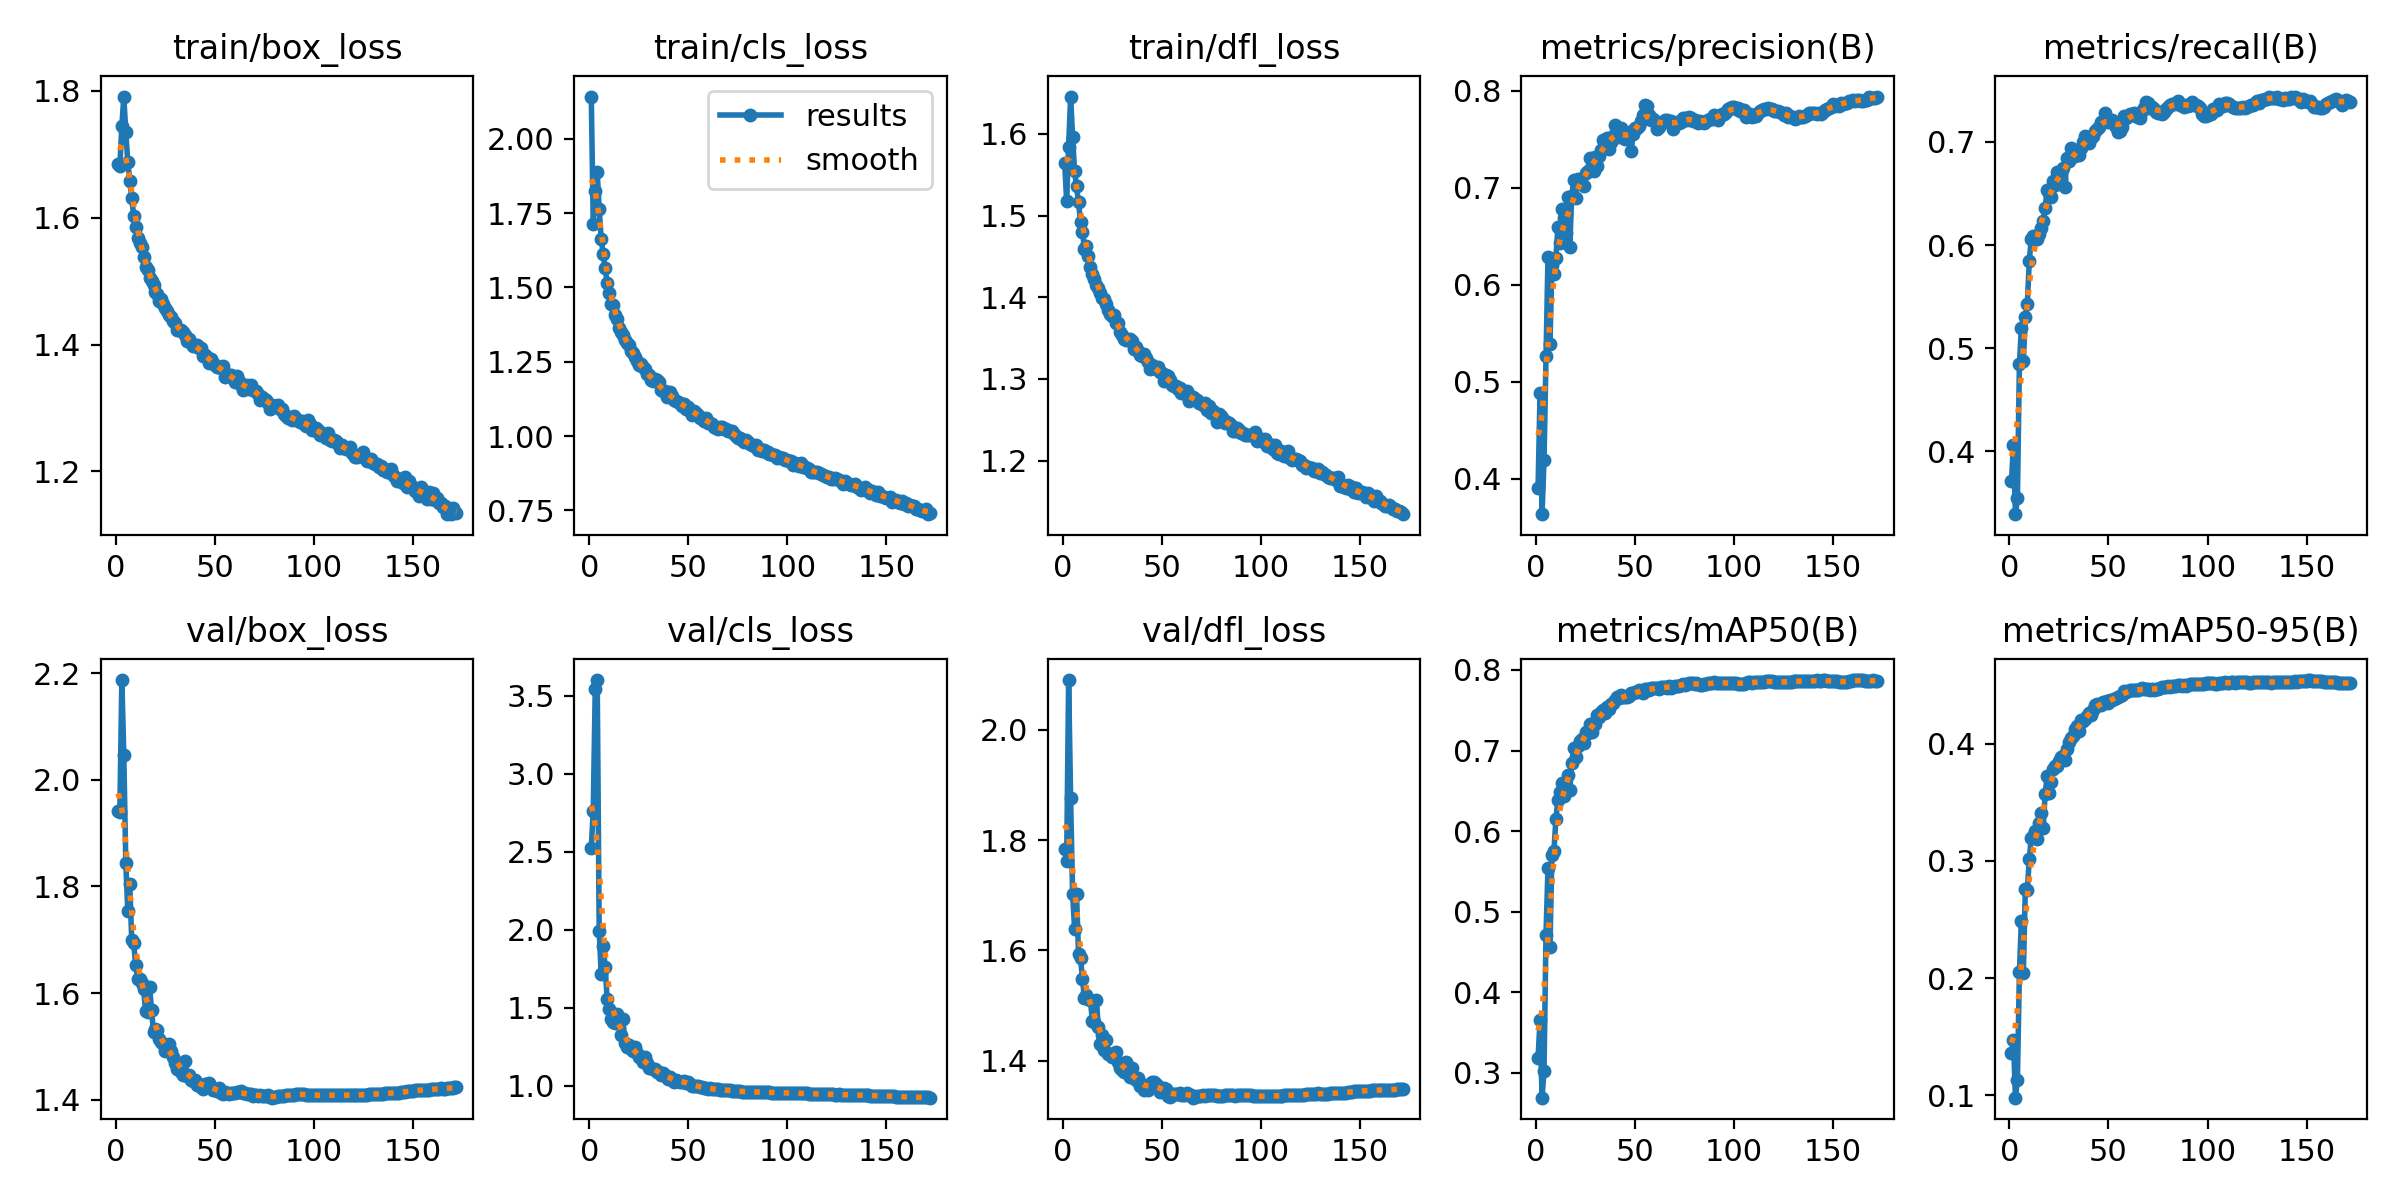

evaluation_test/confusion_matrix.png


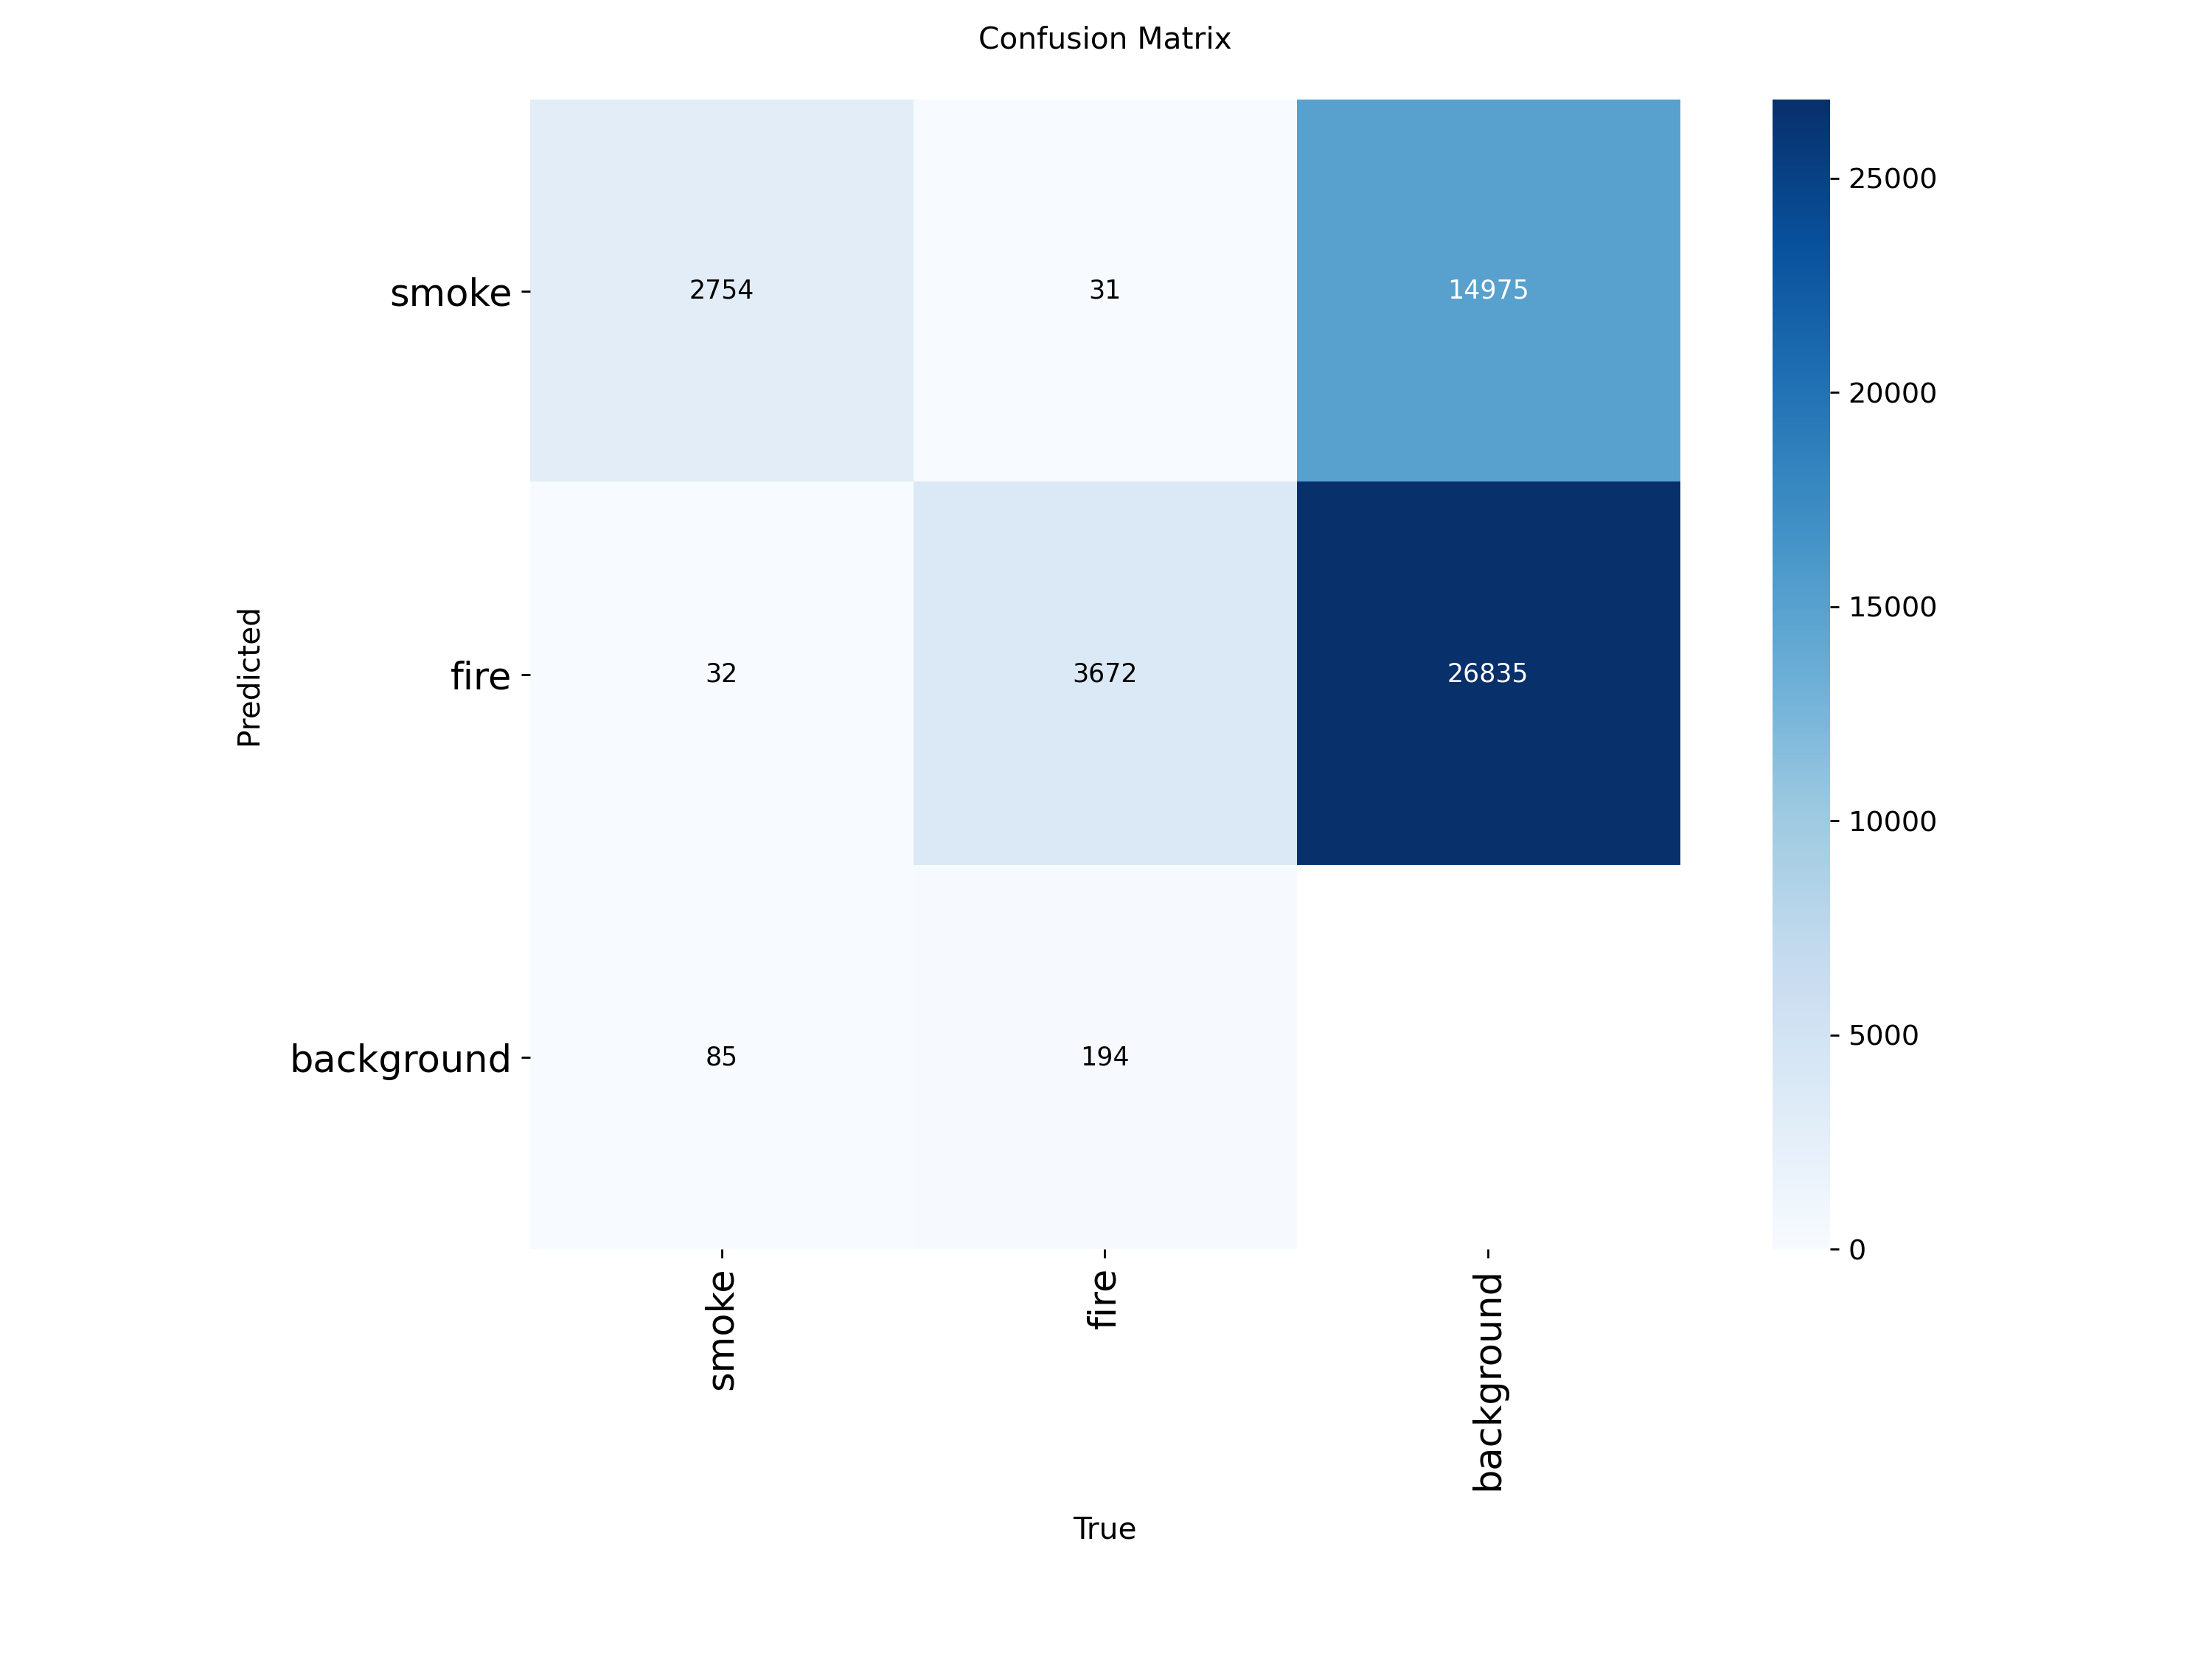

Đã lưu run_summary.json, labelmap.json và biểu đồ.


In [15]:
for relative_path in (
    "train/results.png", "train/confusion_matrix.png",
    "evaluation_val/PR_curve.png", "evaluation_test/confusion_matrix.png",
):
    chart_path = RUN_DIR / relative_path
    if chart_path.is_file():
        print(relative_path)
        display(NotebookImage(filename=str(chart_path), width=700))


def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


run_summary = {
    "run_id": RUN_ID,
    "dataset": str(DATASET_SOURCE),
    "dataset_yaml_sha256": file_sha256(SOURCE_YAML),
    "dataset_images": dataset_rows,
    "transfer_checkpoint_reused": transfer_reused,
    "box_area_by_class": area_table.to_dict(orient="records"),
    "nms_iou_main": NMS_IOU,
    "nms_iou_sweep": list(IOU_SWEEP),
    "deploy_conf_selected_on_val": DEPLOY_CONF,
    "scratch_completed": SCRATCH_PT is not None,
    "scratch_training_seconds": scratch_training_seconds,
    "image_level_test": image_metric_rows,
    "box_recall_by_size_test": size_rows,
    "local_label_fixes": label_fix_summary,
    "class_map": {"0": "smoke", "1": "fire"},
    "model_source": "yolo11n.pt (COCO pretrained)",
    "checkpoint_in_zip": "best.pt",
    "best_checkpoint_sha256": file_sha256(BEST_PT),
    "training": {
        "epochs_max": EPOCHS, "patience": PATIENCE, "imgsz": IMAGE_SIZE,
        "batch": BATCH_SIZE, "seed": SEED, "workers": WORKERS,
        "dataset_copy_seconds": round(copy_seconds, 2),
        "dataset_copy_method": copy_method,
        "duration_seconds": round(training_seconds, 2),
    },
    "evaluation": evaluation,
    "background_test": background_report,
    "software": {
        "python": platform.python_version(),
        "ultralytics": ultralytics.__version__,
        "torch": torch.__version__,
        "gpu": torch.cuda.get_device_name(0),
    },
    "limits": [
        "Confidence chọn bằng max F1 trên val; cần thử thêm trên video thực tế trước triển khai.",
        "Tập test chưa được chứng minh độc lập hoàn toàn theo cảnh/video.",
        "Bảng recall theo kích thước dùng diện tích box chuẩn hóa và confidence triển khai, không phải COCO AP_small/medium/large.",
        "Metrics ảnh có nhãn không phải metrics cảnh báo theo sự kiện video.",
    ],
}
(RUN_DIR / "reports" / "run_summary.json").write_text(
    json.dumps(run_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)
(RUN_DIR / "reports" / "labelmap.json").write_text(
    json.dumps({"0": "smoke", "1": "fire"}, ensure_ascii=False, indent=2), encoding="utf-8"
)
(RUN_DIR / "reports" / "README.md").write_text(
    "# Kết quả YOLO11n FinalSFD smoke/fire\n\n"
    "`best.pt` là checkpoint được chọn bằng validation. `reports/run_summary.json` ghi nguồn dữ liệu, "
    "thông số train, metrics valid/test và SHA-256 checkpoint. `reports/label_fixes.csv` ghi nhãn đã sửa cục bộ. `reports/labelmap.json` ghi thứ tự lớp "
    "0=smoke, 1=fire. Các file `evaluation_*` là biểu đồ đánh giá. "
    "Ảnh mẫu, ảnh sai, bảng mức ảnh và khảo sát NMS ở `reports/`. "
    "Không dùng metrics ảnh làm kết luận độ chính xác cảnh báo video.\n",
    encoding="utf-8",
)
print("Đã lưu run_summary.json, labelmap.json và biểu đồ.")

## Đóng gói và dọn bộ nhớ

Chỉ ZIP cuối được giữ trong `/kaggle/working`. Bước dọn dẹp chỉ xóa đúng `RUN_DIR` do notebook này tạo, sau khi kiểm tra ZIP qua CRC và xác nhận có `best.pt` cùng báo cáo. Không xóa Kaggle Input hoặc file kết quả khác.

In [16]:
def package_and_cleanup(run_dir: Path, final_zip: Path, working_root: Path) -> dict:
    base = working_root.resolve()
    target = run_dir.resolve()
    if target.parent != base or run_dir.is_symlink() or not target.name.startswith("final_sfd_yolo11n_"):
        raise RuntimeError(f"Từ chối xóa thư mục ngoài run được tạo: {target}")
    if final_zip.resolve().parent != base or final_zip.exists():
        raise RuntimeError(f"Đường dẫn ZIP không hợp lệ hoặc đã tồn tại: {final_zip}")

    temporary_zip = final_zip.with_suffix(".zip.part")
    if temporary_zip.exists():
        raise FileExistsError(f"File đóng gói tạm đã tồn tại: {temporary_zip}")
    excluded_names = {"last.pt", "yolo11n.pt"}
    with zipfile.ZipFile(temporary_zip, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6, allowZip64=True) as archive:
        for path in sorted(target.rglob("*")):
            if (not path.is_file() or path.is_symlink() or path.name in excluded_names
                    or path.suffix == ".cache" or path.relative_to(target).parts[0] == "dataset_local"):
                continue
            relative_path = path.relative_to(target)
            archive_path = "best.pt" if path.resolve() == BEST_PT.resolve() else relative_path.as_posix()
            archive.write(path, archive_path)

    with zipfile.ZipFile(temporary_zip) as archive:
        bad_member = archive.testzip()
        required = {"best.pt", "reports/run_summary.json", "reports/labelmap.json", "reports/metrics_comparison.csv", "reports/nms_iou_sweep.csv", "reports/test_image_metrics.csv", "reports/test_box_recall_by_size.csv"}
        missing = required - set(archive.namelist())
        if bad_member or missing:
            raise RuntimeError(f"ZIP không đạt kiểm tra: bad_member={bad_member}, thiếu={sorted(missing)}")
        packaged_files = len(archive.namelist())
    # Chỉ thay file tạm bằng ZIP cuối khi CRC và các file bắt buộc đều đạt.
    os.replace(temporary_zip, final_zip)
    if not final_zip.is_file():
        raise RuntimeError("Chưa thấy ZIP cuối; giữ thư mục run để kiểm tra")

    # Chỉ xóa thư mục run do notebook tạo; Kaggle Input và ZIP cuối được giữ.
    os.chdir(base)
    shutil.rmtree(target)
    return {"zip": str(final_zip), "bytes": final_zip.stat().st_size, "files": packaged_files,
            "run_directory_removed": not target.exists()}


package_result = package_and_cleanup(RUN_DIR, RESULT_ZIP, WORK_ROOT)
display(pd.DataFrame([package_result]))
display(FileLink(str(RESULT_ZIP)))

,zip,bytes,files,run_directory_removed
0,/kaggle/working/final_sfd_yolo11n_20261112_170...,34375910,162,True


/kaggle/working/final_sfd_yolo11n_20261112_170520_results.zip